# 🛡️ Project Sentinel: Hazardous Asteroid Prediction AI
### NASA Near-Earth Object (NEO) Classification — Capstone Project

---

**Objective:** Develop a supervised Machine Learning system to classify whether a Near Earth Object (NEO) is **Hazardous** or **Non-Hazardous** based on its physical and orbital characteristics.

| Field | Detail |
|---|---|
| **Dataset** | NASA Near Earth Objects (NEO) |
| **Task** | Binary Classification |
| **Target** | `hazardous` (True / False) |
| **Notebook** | `hazardous_asteroid_prediction_final.ipynb` |

---

---
## 📦 Phase 1: Data Preparation & Preprocessing

> Load the dataset, handle missing values, remove unnecessary attributes, encode categoricals, and scale features.

In [1]:
# ── Core Imports ──────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay, f1_score, accuracy_score)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import joblib
import os

# ── Plot style ────────────────────────────────────────────────
sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

print("✅ All libraries imported successfully!")
print(f"   pandas  : {pd.__version__}")
print(f"   numpy   : {np.__version__}")
print(f"   sklearn : __version__ not exposed in all builds — OK")


✅ All libraries imported successfully!
   pandas  : 3.0.6
   numpy   : 2.4.6
   sklearn : __version__ not exposed in all builds — OK


In [2]:
# ── 1.1  Load Dataset ─────────────────────────────────────────
CSV_PATH = "neo (3).csv"
df = pd.read_csv(CSV_PATH)

print(f"📊 Dataset shape : {df.shape[0]:,} rows  ×  {df.shape[1]} columns")
print(f"📋 Columns       : {list(df.columns)}")
df.head()


📊 Dataset shape : 90,836 rows  ×  10 columns
📋 Columns       : ['id', 'name', 'est_diameter_min', 'est_diameter_max', 'relative_velocity', 'miss_distance', 'orbiting_body', 'sentry_object', 'absolute_magnitude', 'hazardous']


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True


In [3]:
# ── 1.2  Basic Info ───────────────────────────────────────────
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90836 non-null  int64  
 1   name                90836 non-null  str    
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90836 non-null  float64
 4   relative_velocity   90836 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   orbiting_body       90836 non-null  str    
 7   sentry_object       90836 non-null  bool   
 8   absolute_magnitude  90836 non-null  float64
 9   hazardous           90836 non-null  bool   
dtypes: bool(2), float64(5), int64(1), str(2)
memory usage: 5.7 MB


In [4]:
# ── 1.3  Missing Values ───────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0]

if missing_df.empty:
    print("✅ No missing values found in the dataset.")
else:
    print("⚠️  Missing values detected:")
    print(missing_df)
    df.dropna(inplace=True)
    print(f"\n✅ After drop: {df.shape}")


✅ No missing values found in the dataset.


In [5]:
# ── 1.4  Remove Unnecessary Columns ──────────────────────────
# 'id'           → arbitrary identifier, not predictive
# 'name'         → text label, not predictive
# 'orbiting_body'→ all rows = 'Earth', zero variance
# 'sentry_object'→ all values = False, zero variance

cols_to_drop = ['id', 'name', 'orbiting_body', 'sentry_object']
df.drop(columns=cols_to_drop, inplace=True)

print(f"✅ Dropped columns : {cols_to_drop}")
print(f"📐 Remaining shape : {df.shape}")
df.head()


✅ Dropped columns : ['id', 'name', 'orbiting_body', 'sentry_object']
📐 Remaining shape : (90836, 6)


,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,1.198271,2.679415,13569.249224,5.483974e+07,16.73,False
1,0.265800,0.594347,73588.726663,6.143813e+07,20.00,True
2,0.722030,1.614507,114258.692129,4.979872e+07,17.83,False
3,0.096506,0.215794,24764.303138,2.543497e+07,22.20,False
4,0.255009,0.570217,42737.733765,4.627557e+07,20.09,True


In [6]:
# ── 1.5  Encode Target Variable ───────────────────────────────
# hazardous: True → 1, False → 0
df['hazardous'] = df['hazardous'].astype(int)

print("Target value counts after encoding:")
print(df['hazardous'].value_counts())
print(f"\nData types:\n{df.dtypes}")


Target value counts after encoding:
hazardous
0    81996
1     8840
Name: count, dtype: int64

Data types:
est_diameter_min      float64
est_diameter_max      float64
relative_velocity     float64
miss_distance         float64
absolute_magnitude    float64
hazardous               int64
dtype: object


In [7]:
# ── 1.6  Descriptive Statistics ───────────────────────────────
df.describe().T.style.background_gradient(cmap='Blues')


,count,mean,std,min,25%,50%,75%,max
est_diameter_min,90836.000000,0.127432,0.298511,0.000609,0.019256,0.048368,0.143402,37.892650
est_diameter_max,90836.000000,0.284947,0.667491,0.001362,0.043057,0.108153,0.320656,84.730541
relative_velocity,90836.000000,48066.918918,25293.296961,203.346433,28619.020645,44190.117890,62923.604633,236990.128088
miss_distance,90836.000000,37066546.030422,22352040.599190,6745.532516,17210820.235765,37846579.263426,56548996.451399,74798651.452197
absolute_magnitude,90836.000000,23.527103,2.894086,9.230000,21.340000,23.700000,25.700000,33.200000
hazardous,90836.000000,0.097318,0.296392,0.000000,0.000000,0.000000,0.000000,1.000000


In [8]:
# ── 1.7  Feature / Target Split & Scaling ─────────────────────
FEATURES = ['est_diameter_min', 'est_diameter_max', 'relative_velocity',
            'miss_distance', 'absolute_magnitude']
TARGET   = 'hazardous'

X = df[FEATURES].copy()
y = df[TARGET].copy()

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=FEATURES)

print(f"✅ Feature matrix : {X_scaled.shape}")
print(f"✅ Target vector  : {y.shape}")
X_scaled.describe().round(3)


✅ Feature matrix : (90836, 5)
✅ Target vector  : (90836,)


,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude
count,90836.000,90836.000,90836.000,90836.000,90836.000
mean,-0.000,-0.000,0.000,-0.000,0.000
std,1.000,1.000,1.000,1.000,1.000
min,-0.425,-0.425,-1.892,-1.658,-4.940
25%,-0.362,-0.362,-0.769,-0.888,-0.756
50%,-0.265,-0.265,-0.153,0.035,0.060
75%,0.053,0.053,0.587,0.872,0.751
max,126.513,126.513,7.469,1.688,3.342


---
## 🔍 Phase 2: Exploratory Data Analysis (EDA)

> Analyze class distributions, visualize feature relationships, and extract insights about hazardous vs. non-hazardous objects.

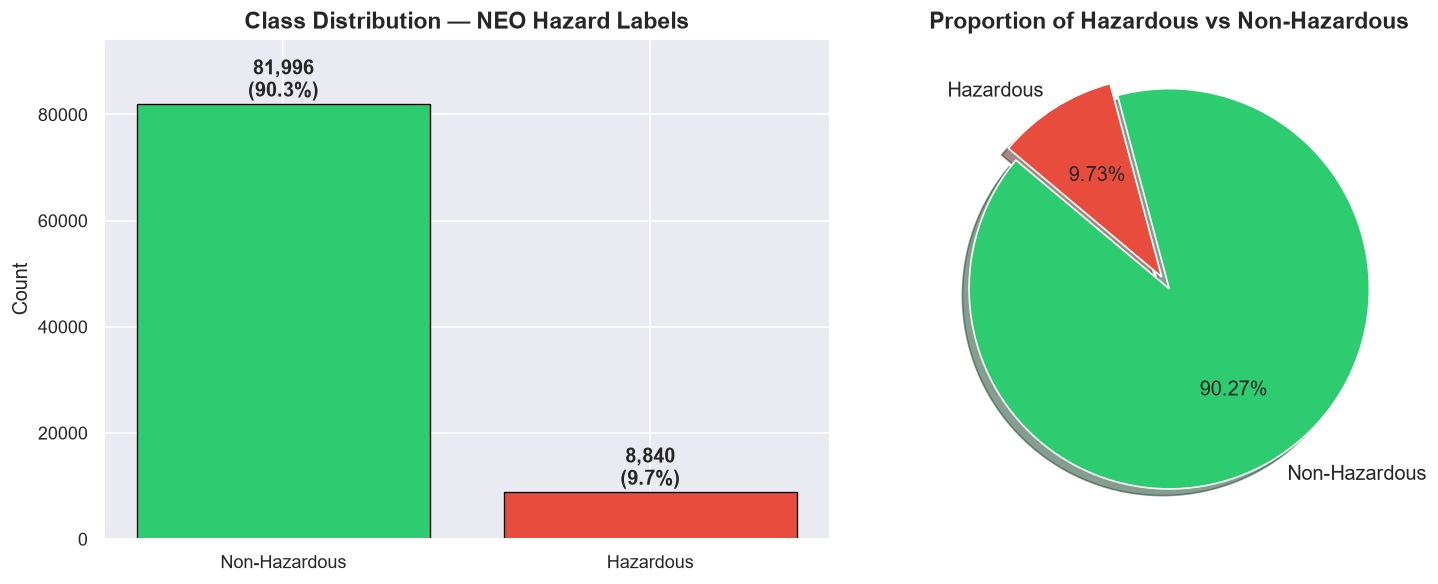


⚠️  Class imbalance ratio  →  1 : 9


In [9]:
# ── 2.1  Class Distribution ───────────────────────────────────
labels = ['Non-Hazardous', 'Hazardous']
counts = y.value_counts().sort_index()
colors = ['#2ecc71', '#e74c3c']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart
axes[0].bar(labels, counts.values, color=colors, edgecolor='black', linewidth=0.8)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 300, f'{v:,}\n({v/len(y)*100:.1f}%)',
                 ha='center', va='bottom', fontweight='bold', fontsize=12)
axes[0].set_title('Class Distribution — NEO Hazard Labels', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_ylim(0, max(counts.values) * 1.15)

# Pie chart
wedges, texts, autotexts = axes[1].pie(
    counts.values, labels=labels, colors=colors, autopct='%1.2f%%',
    startangle=140, textprops={'fontsize': 12},
    explode=(0, 0.07), shadow=True)
axes[1].set_title('Proportion of Hazardous vs Non-Hazardous', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('phase2_class_distribution.png', bbox_inches='tight')
plt.show()
print(f"\n⚠️  Class imbalance ratio  →  1 : {counts[0]//counts[1]}")


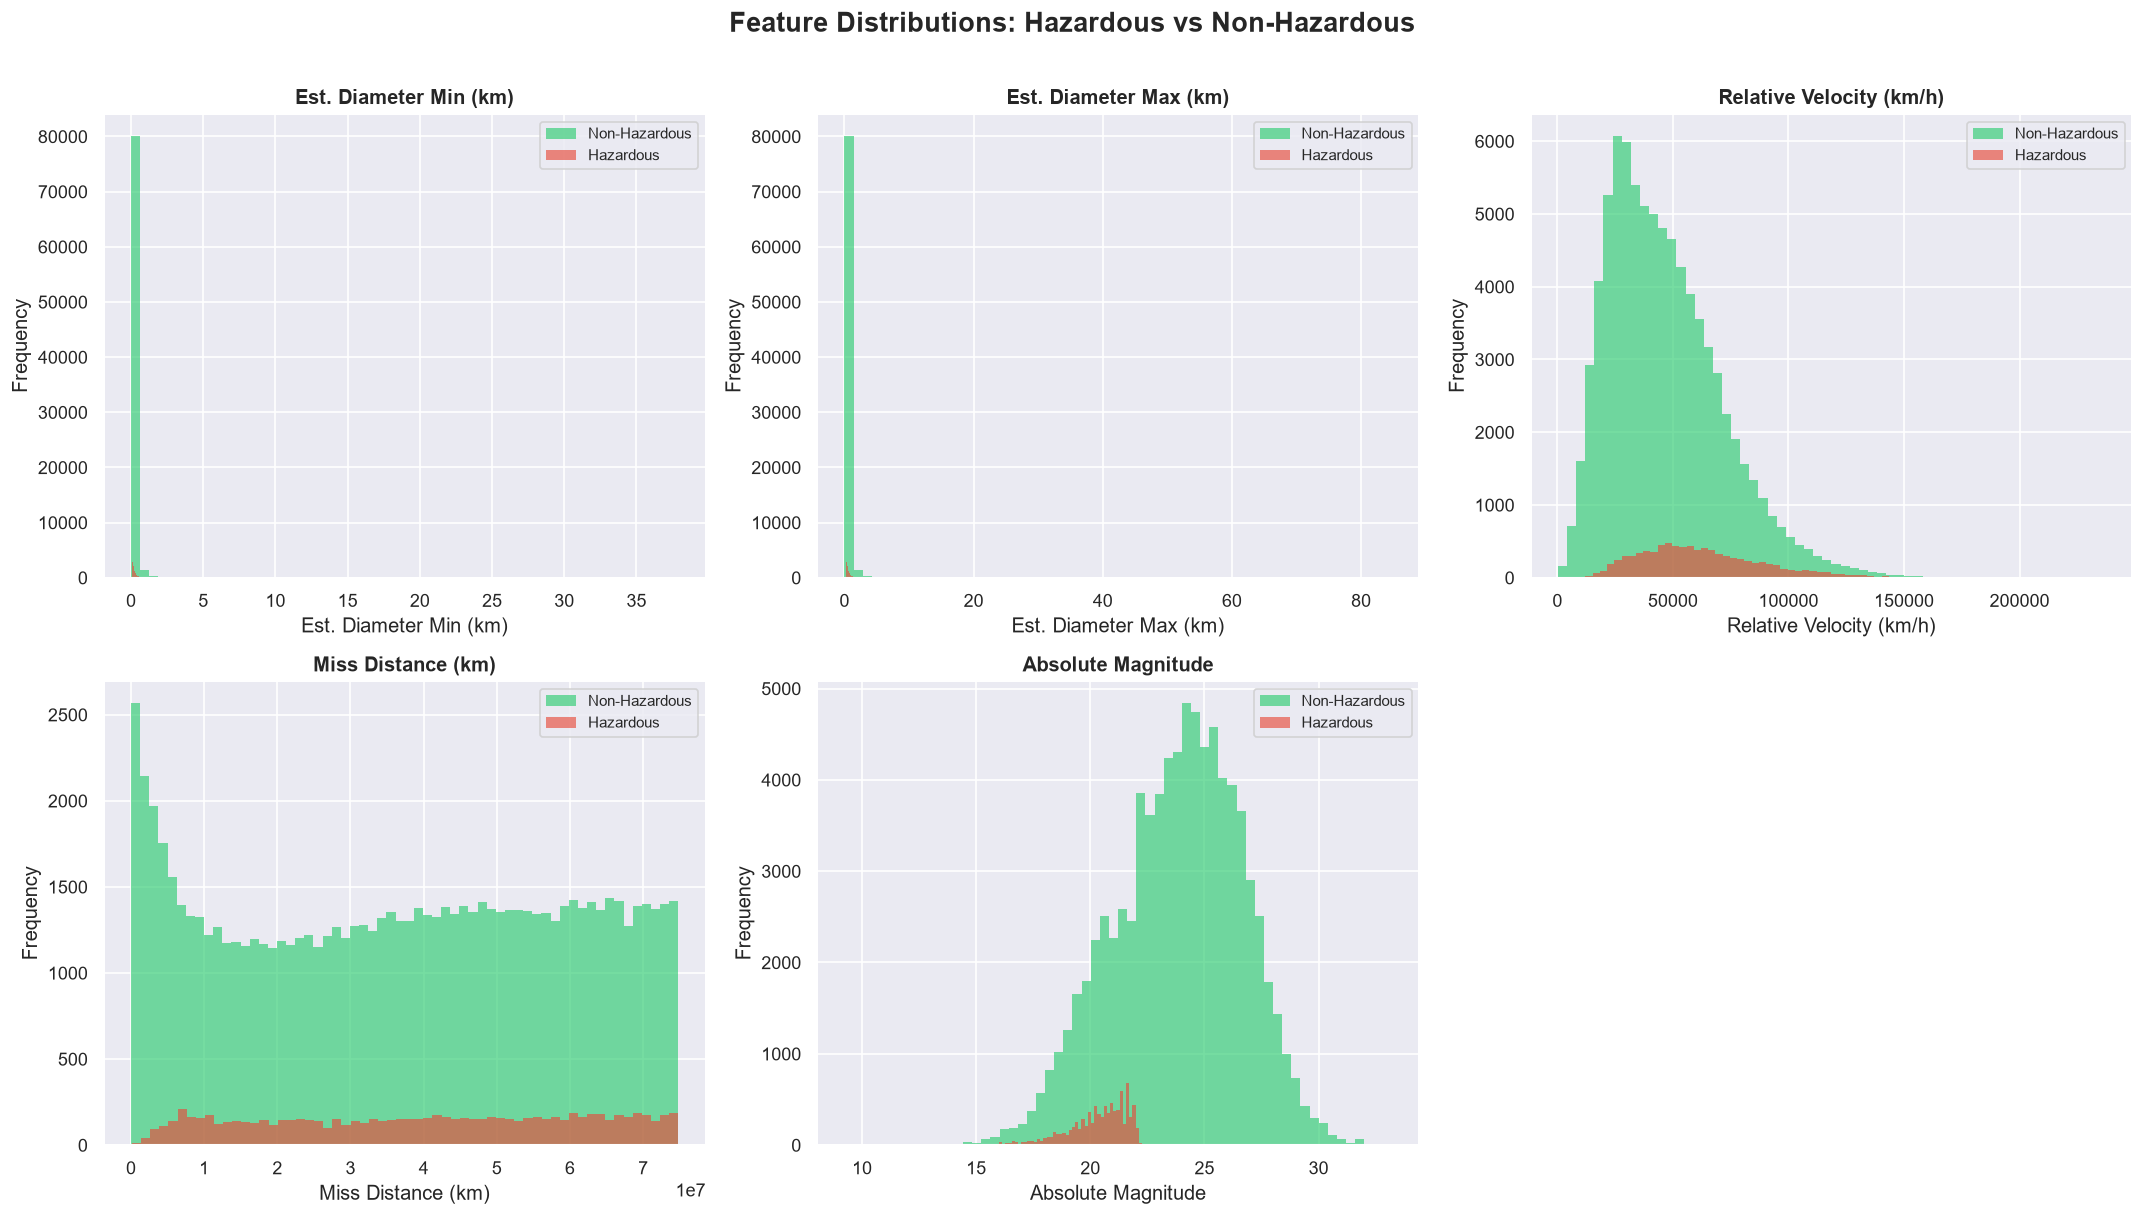

In [10]:
# ── 2.2  Feature Distributions by Class ──────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

feature_labels = {
    'est_diameter_min'  : 'Est. Diameter Min (km)',
    'est_diameter_max'  : 'Est. Diameter Max (km)',
    'relative_velocity' : 'Relative Velocity (km/h)',
    'miss_distance'     : 'Miss Distance (km)',
    'absolute_magnitude': 'Absolute Magnitude'
}

for ax, (feat, label) in zip(axes, feature_labels.items()):
    for val, color, name in [(0, '#2ecc71', 'Non-Hazardous'),
                              (1, '#e74c3c', 'Hazardous')]:
        data = df.loc[df['hazardous'] == val, feat]
        ax.hist(data, bins=60, alpha=0.65, color=color, label=name, edgecolor='none')
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel(label)
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=9)

# Turn off unused subplot
axes[-1].axis('off')

fig.suptitle('Feature Distributions: Hazardous vs Non-Hazardous',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('phase2_feature_distributions.png', bbox_inches='tight')
plt.show()


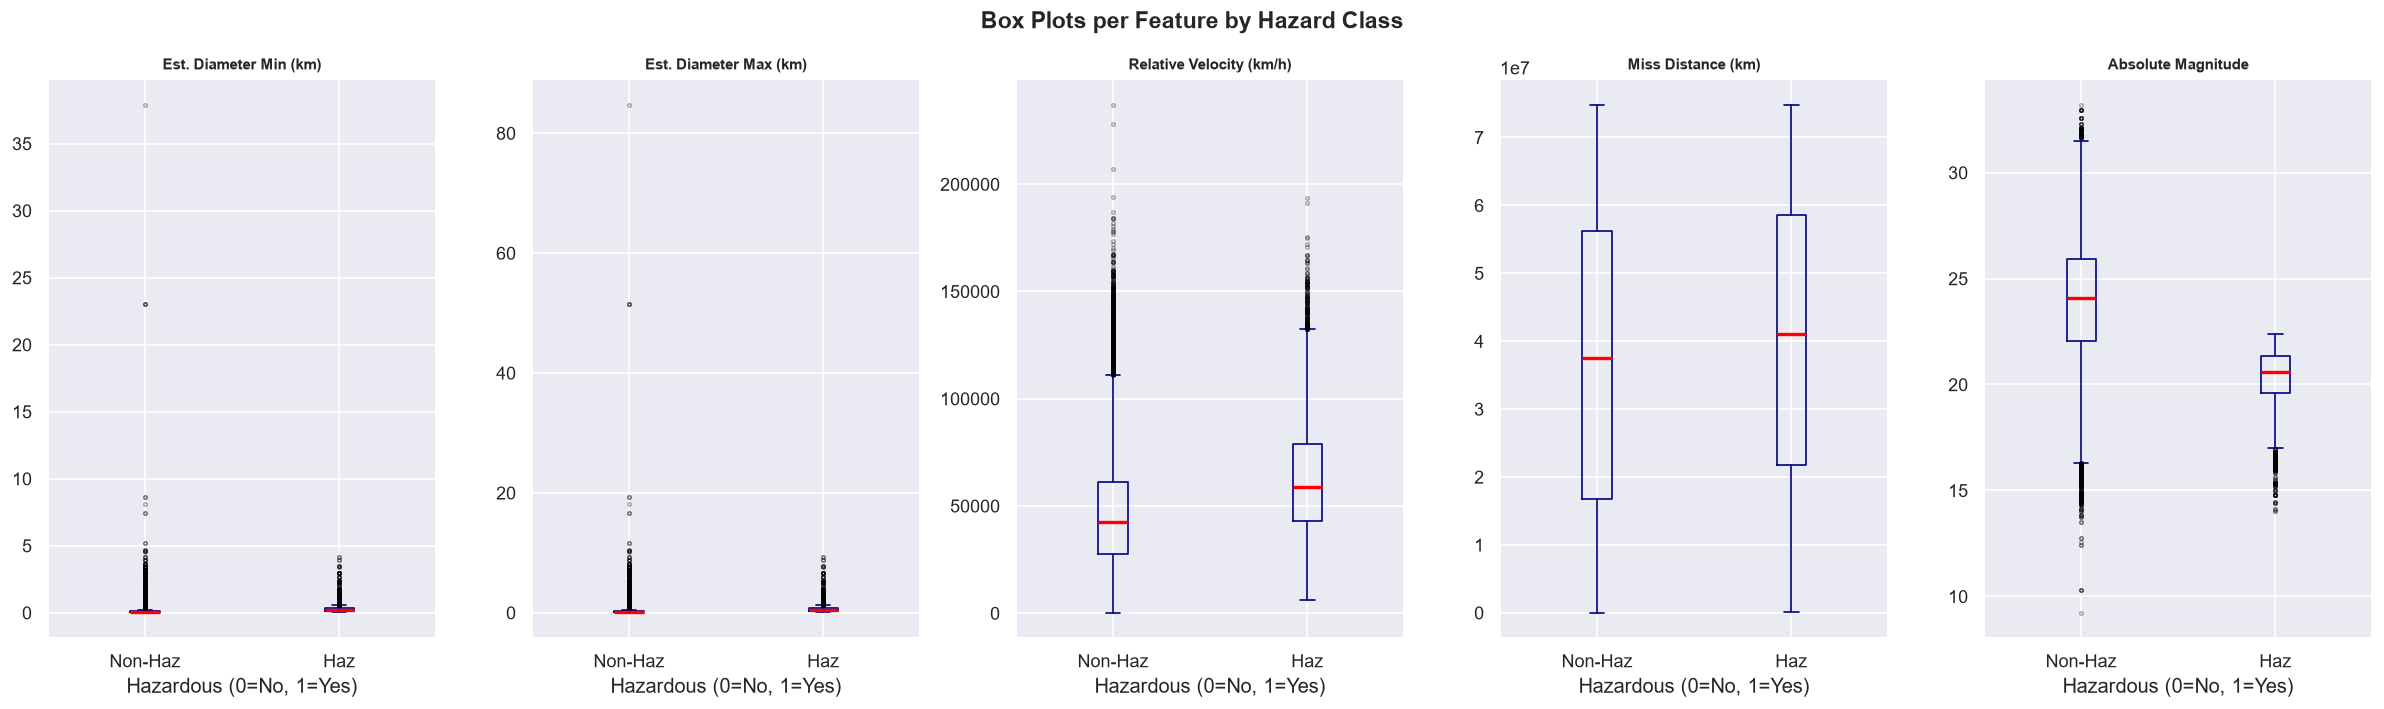

In [11]:
# ── 2.3  Box Plots — Outlier Analysis ────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for ax, (feat, label) in zip(axes, feature_labels.items()):
    df.boxplot(column=feat, by='hazardous', ax=ax,
               boxprops=dict(color='navy'),
               medianprops=dict(color='red', linewidth=2),
               whiskerprops=dict(color='navy'),
               capprops=dict(color='navy'),
               flierprops=dict(marker='o', markersize=2, alpha=0.3))
    ax.set_title(label, fontsize=9, fontweight='bold')
    ax.set_xlabel('Hazardous (0=No, 1=Yes)')
    ax.set_xticklabels(['Non-Haz', 'Haz'])

fig.suptitle('Box Plots per Feature by Hazard Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('phase2_boxplots.png', bbox_inches='tight')
plt.show()


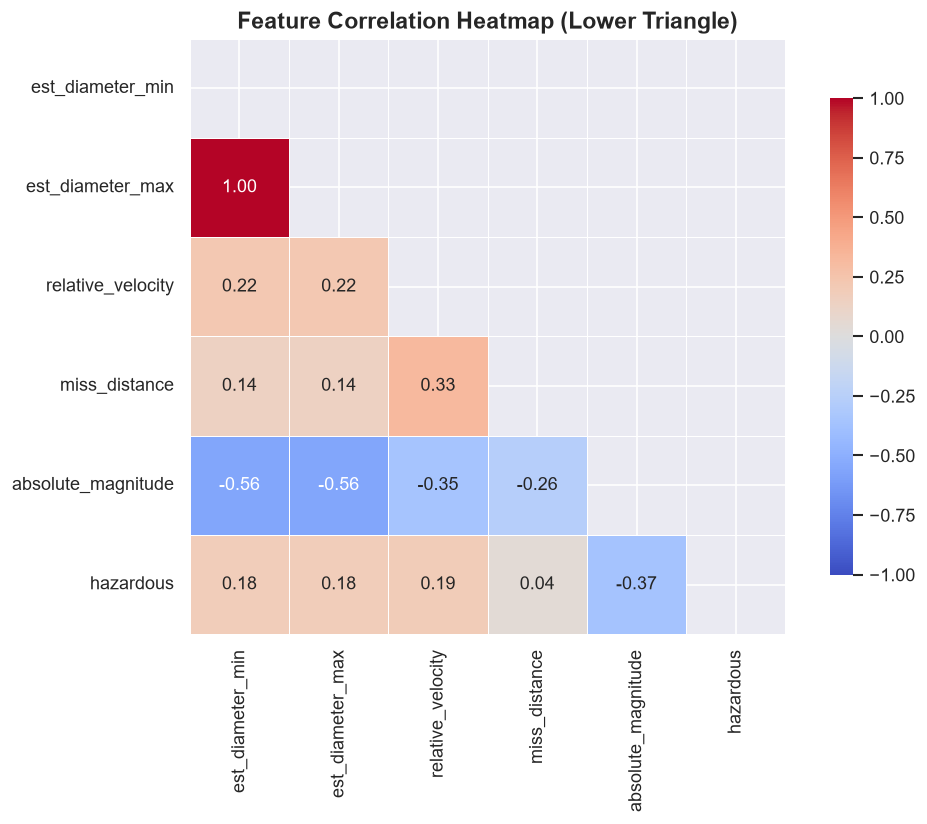

In [12]:
# ── 2.4  Correlation Heatmap ──────────────────────────────────
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, ax=ax, linewidths=0.5, square=True,
            cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Heatmap (Lower Triangle)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('phase2_correlation_heatmap.png', bbox_inches='tight')
plt.show()


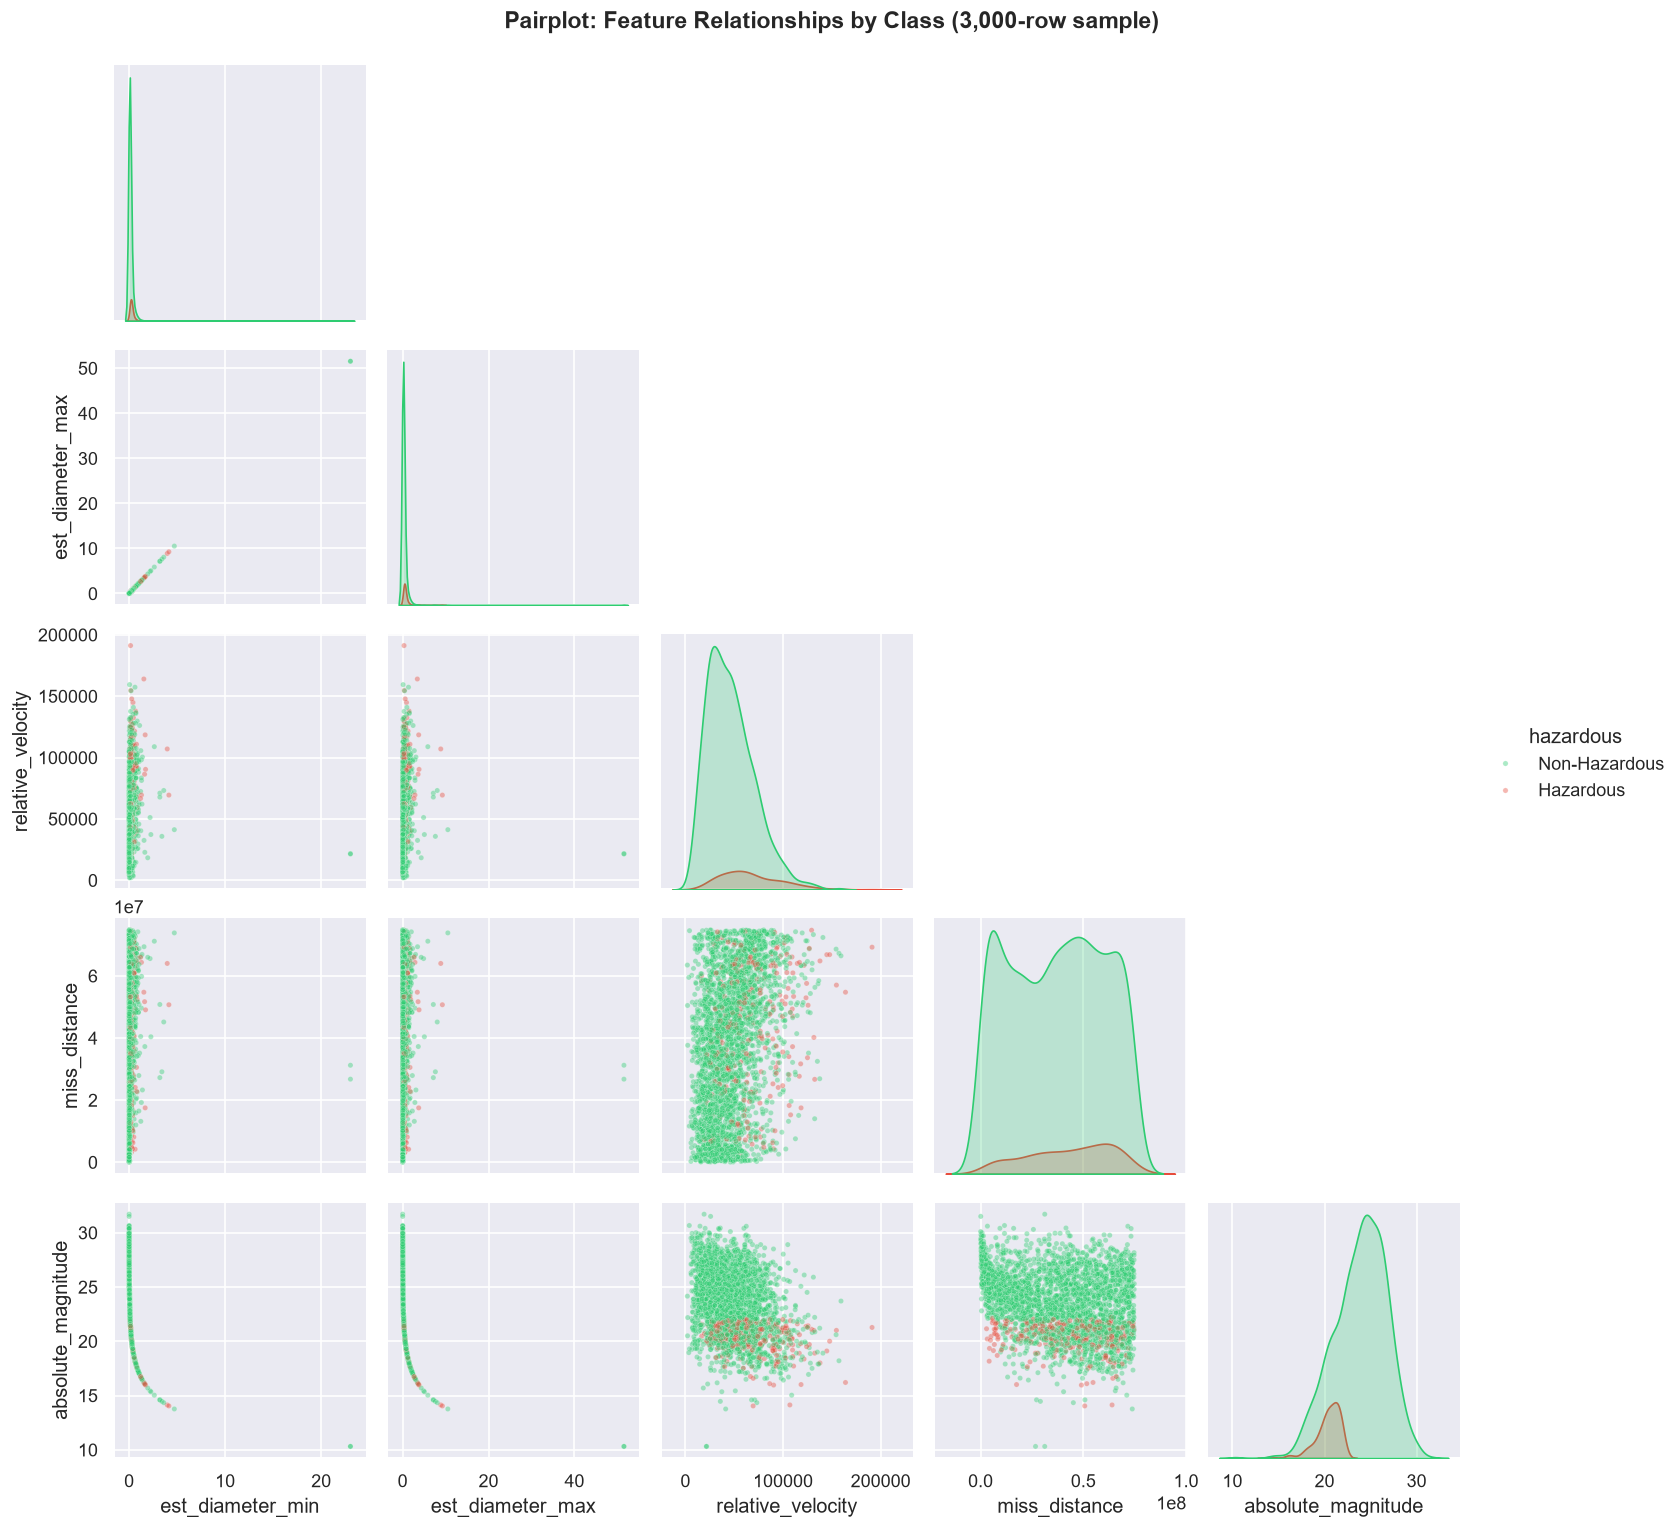

In [13]:
# ── 2.5  Pairplot (sampled for performance) ───────────────────
sample = df.sample(n=3000, random_state=42)
pairplot_df = sample[FEATURES + ['hazardous']].copy()
pairplot_df['hazardous'] = pairplot_df['hazardous'].map({0: 'Non-Hazardous', 1: 'Hazardous'})

g = sns.pairplot(pairplot_df, hue='hazardous', corner=True,
                 palette={'Non-Hazardous': '#2ecc71', 'Hazardous': '#e74c3c'},
                 plot_kws={'alpha': 0.4, 's': 10},
                 diag_kind='kde')
g.figure.suptitle('Pairplot: Feature Relationships by Class (3,000-row sample)',
                   y=1.02, fontsize=14, fontweight='bold')
plt.savefig('phase2_pairplot.png', bbox_inches='tight')
plt.show()


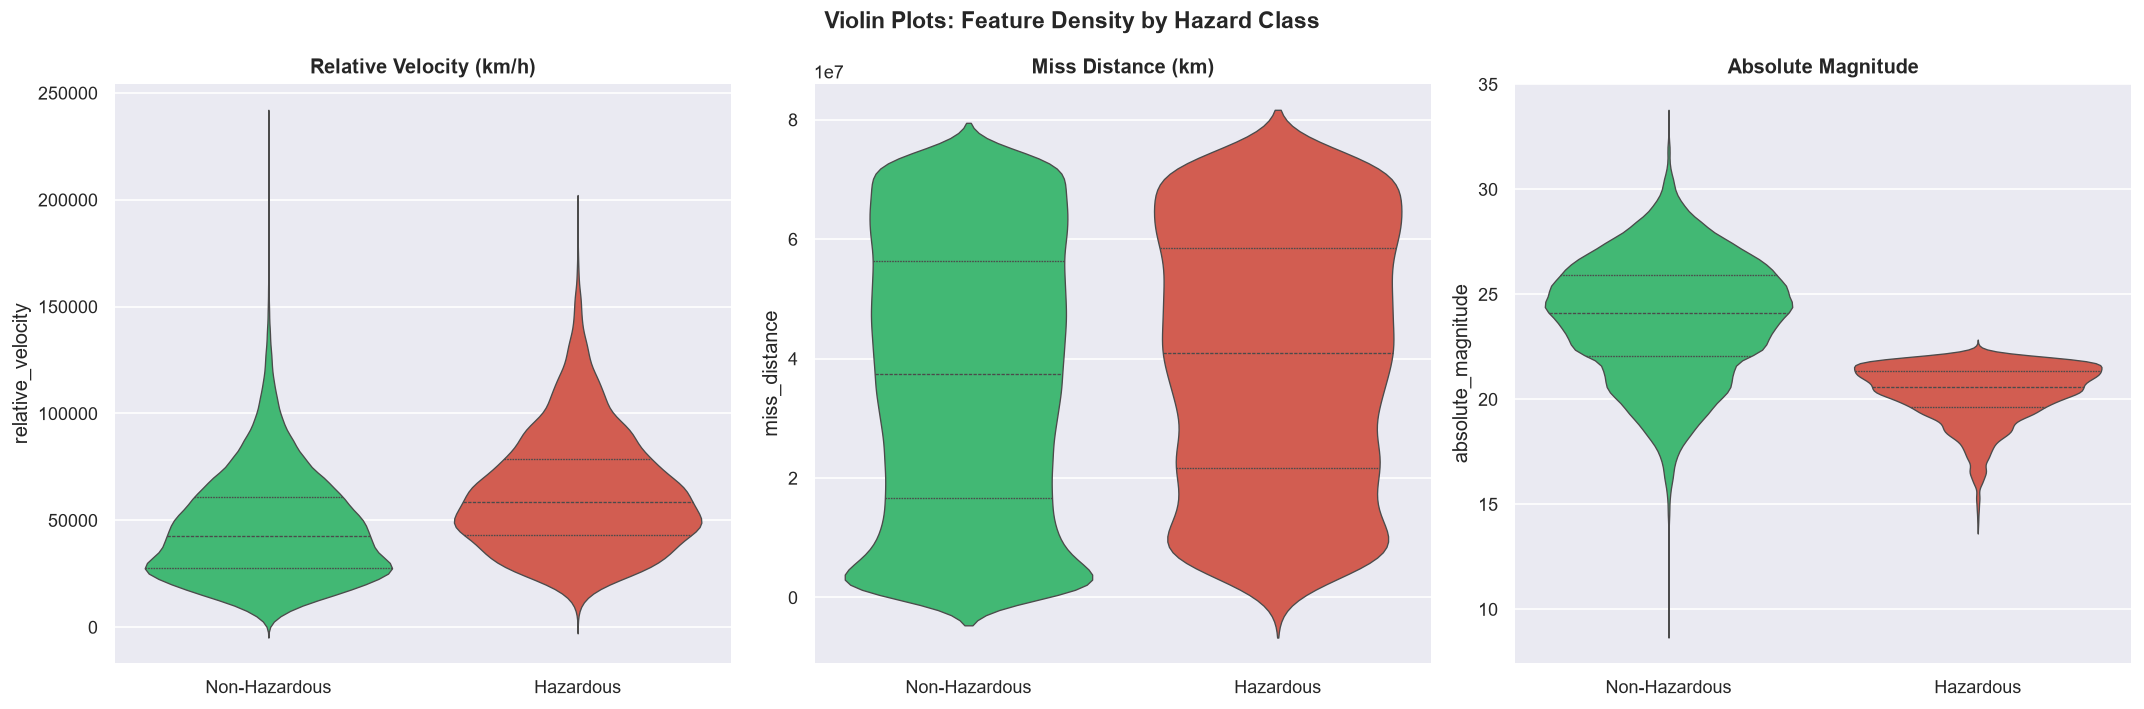

In [14]:
# ── 2.6  Violin Plots ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

violin_features = ['relative_velocity', 'miss_distance', 'absolute_magnitude']
violin_labels   = ['Relative Velocity (km/h)', 'Miss Distance (km)', 'Absolute Magnitude']

for ax, feat, label in zip(axes, violin_features, violin_labels):
    temp = df[[feat, 'hazardous']].copy()
    temp['Class'] = temp['hazardous'].map({0: 'Non-Hazardous', 1: 'Hazardous'})
    sns.violinplot(data=temp, x='Class', y=feat, ax=ax,
                   palette={'Non-Hazardous': '#2ecc71', 'Hazardous': '#e74c3c'},
                   inner='quartile', linewidth=0.8)
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('')

fig.suptitle('Violin Plots: Feature Density by Hazard Class',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('phase2_violin_plots.png', bbox_inches='tight')
plt.show()


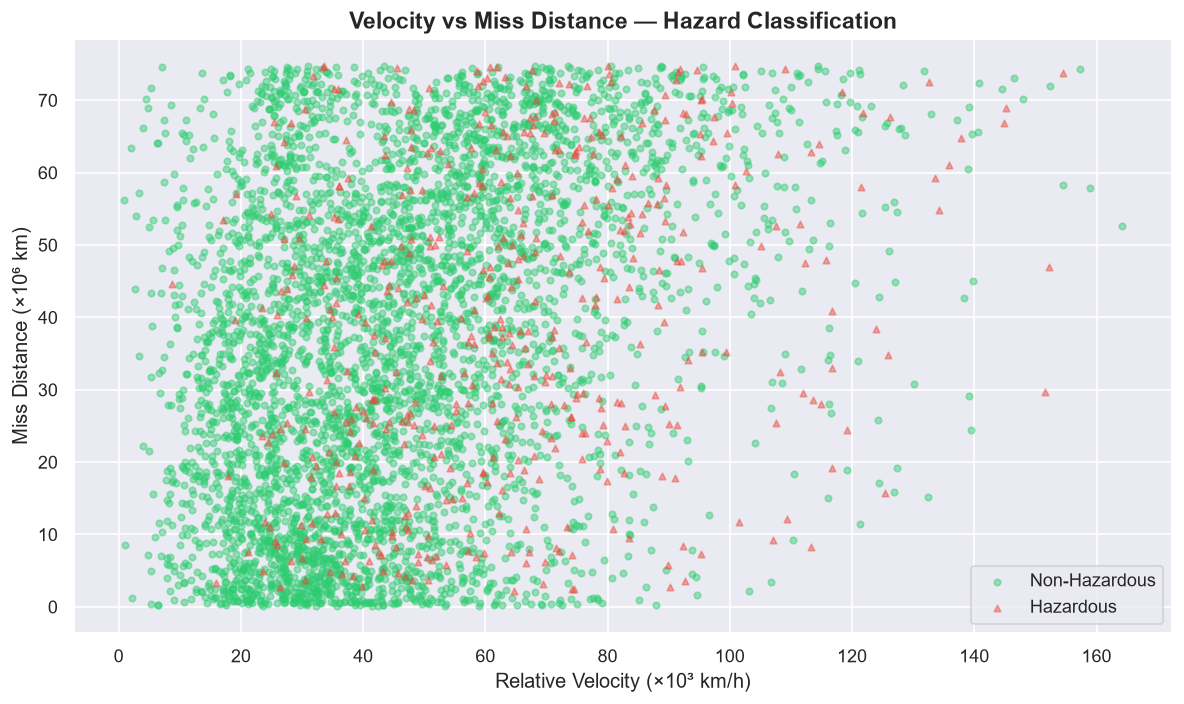

In [15]:
# ── 2.7  Scatter: Velocity vs Miss Distance ───────────────────
sample2 = df.sample(n=5000, random_state=7)

fig, ax = plt.subplots(figsize=(10, 6))
for label, color, marker in [(0, '#2ecc71', 'o'), (1, '#e74c3c', '^')]:
    sub = sample2[sample2['hazardous'] == label]
    ax.scatter(sub['relative_velocity'] / 1000, sub['miss_distance'] / 1e6,
               c=color, marker=marker, alpha=0.45, s=15,
               label='Non-Hazardous' if label == 0 else 'Hazardous')

ax.set_xlabel('Relative Velocity (×10³ km/h)', fontsize=12)
ax.set_ylabel('Miss Distance (×10⁶ km)', fontsize=12)
ax.set_title('Velocity vs Miss Distance — Hazard Classification',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('phase2_scatter_velocity_distance.png', bbox_inches='tight')
plt.show()


In [16]:
# ── 2.8  Summary Statistics by Class ─────────────────────────
summary = df.groupby('hazardous')[FEATURES].agg(['mean', 'median', 'std']).round(4)
summary.index = ['Non-Hazardous', 'Hazardous']
print("\n📊 Feature Summary Statistics by Class:\n")
summary.style.background_gradient(cmap='RdYlGn', axis=0)



📊 Feature Summary Statistics by Class:



---
## ⚙️ Phase 3: Feature Engineering & Selection

> Engineer new features, evaluate correlations, remove redundant attributes, and prepare the final feature matrix.

In [17]:
# ── 3.1  Engineer New Features ────────────────────────────────
df_eng = df.copy()

# Mean diameter — combines min and max into a single size estimate
df_eng['diameter_mean'] = (df_eng['est_diameter_min'] + df_eng['est_diameter_max']) / 2

# Diameter range — captures uncertainty / size spread
df_eng['diameter_range'] = df_eng['est_diameter_max'] - df_eng['est_diameter_min']

# Threat index — higher velocity & smaller miss distance = more threat
df_eng['threat_index'] = df_eng['relative_velocity'] / (df_eng['miss_distance'] + 1)

print("✅ Engineered Features Added:")
print("   • diameter_mean  — average of min & max diameter")
print("   • diameter_range — spread of size estimate")
print("   • threat_index   — velocity / miss_distance proxy")
df_eng[['diameter_mean', 'diameter_range', 'threat_index', 'hazardous']].describe().round(6)


✅ Engineered Features Added:
   • diameter_mean  — average of min & max diameter
   • diameter_range — spread of size estimate
   • threat_index   — velocity / miss_distance proxy


,diameter_mean,diameter_range,threat_index,hazardous
count,90836.000000,90836.000000,90836.000000,90836.000000
mean,0.206189,0.157515,0.007396,0.097318
std,0.483001,0.368980,0.077571,0.296392
min,0.000985,0.000753,0.000004,0.000000
25%,0.031156,0.023801,0.000842,0.000000
50%,0.078260,0.059786,0.001298,0.000000
75%,0.232029,0.177255,0.002418,0.000000
max,61.311595,46.837891,7.164811,1.000000


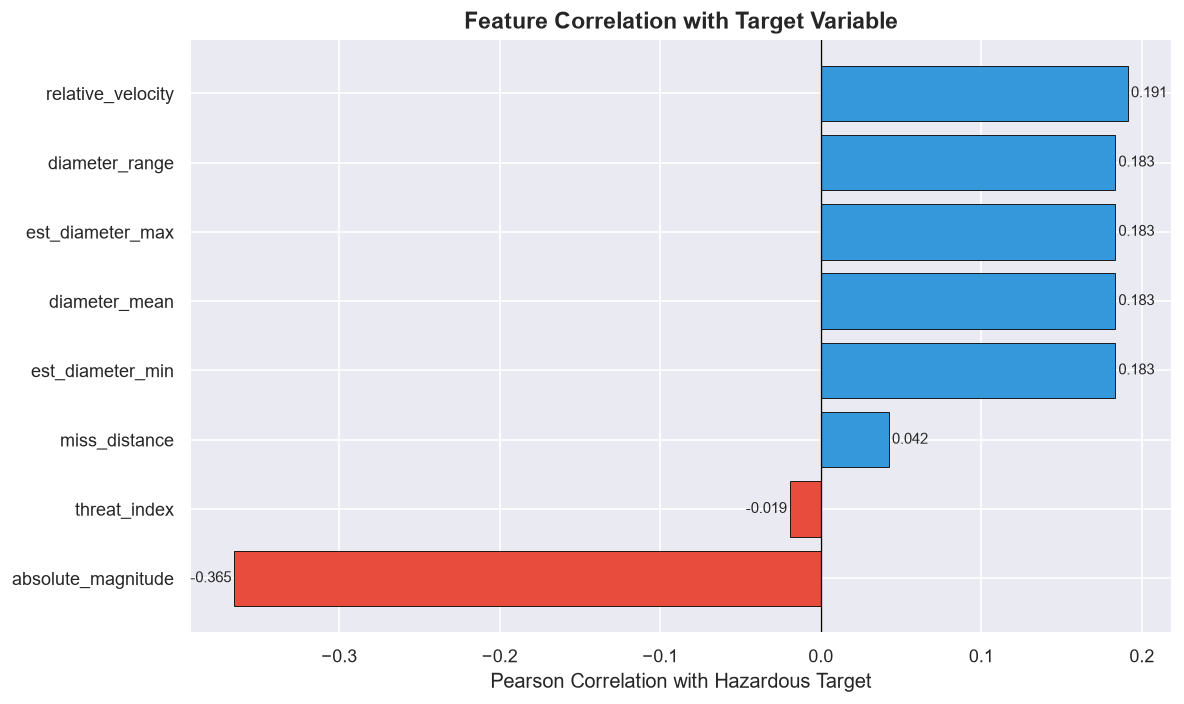

In [18]:
# ── 3.2  Feature Correlation with Target ─────────────────────
correlations = df_eng.corr(numeric_only=True)['hazardous'].drop('hazardous').sort_values()

colors = ['#e74c3c' if c < 0 else '#3498db' for c in correlations]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(correlations.index, correlations.values, color=colors, edgecolor='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Pearson Correlation with Hazardous Target', fontsize=12)
ax.set_title('Feature Correlation with Target Variable', fontsize=14, fontweight='bold')

for bar, val in zip(bars, correlations.values):
    ax.text(val + (0.002 if val >= 0 else -0.002), bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', ha='left' if val >= 0 else 'right', fontsize=9)

plt.tight_layout()
plt.savefig('phase3_target_correlation.png', bbox_inches='tight')
plt.show()


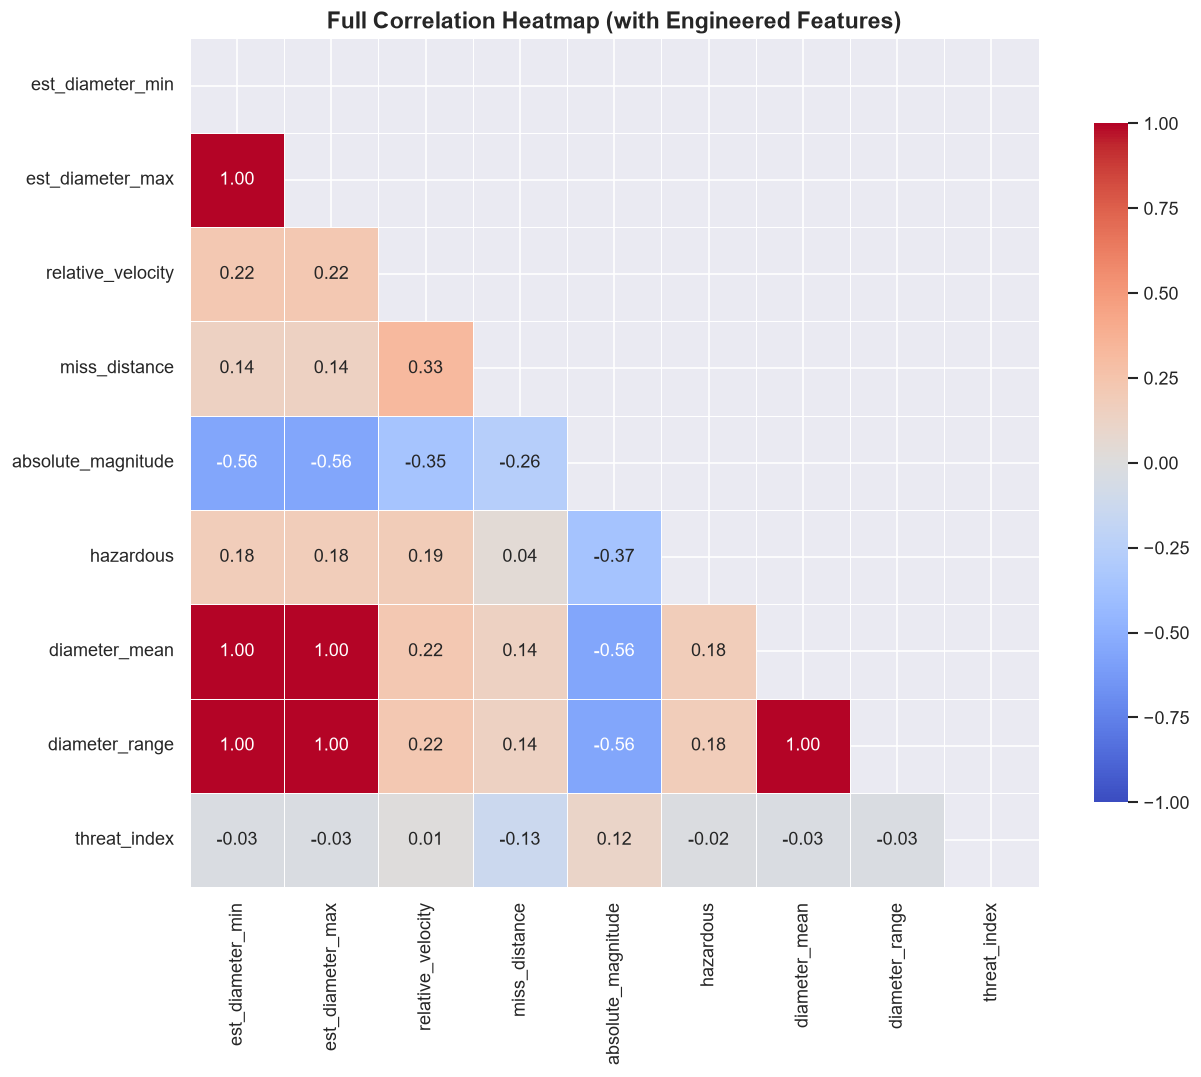

In [19]:
# ── 3.3  Full Correlation Heatmap (with engineered features) ──
corr_eng = df_eng.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_eng, dtype=bool))
sns.heatmap(corr_eng, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, ax=ax, linewidths=0.5, square=True,
            cbar_kws={'shrink': 0.8})
ax.set_title('Full Correlation Heatmap (with Engineered Features)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('phase3_full_correlation.png', bbox_inches='tight')
plt.show()


In [20]:
# ── 3.4  Select Final Feature Set ────────────────────────────
# Remove est_diameter_min & est_diameter_max (replaced by diameter_mean & diameter_range)
# Remove sentry_object & orbiting_body (already dropped, zero-variance)
# Retain all others including engineered features

FINAL_FEATURES = [
    'absolute_magnitude',
    'diameter_mean',
    'diameter_range',
    'relative_velocity',
    'miss_distance',
    'threat_index'
]

X_final = df_eng[FINAL_FEATURES].copy()
y_final = df_eng['hazardous'].copy()

print(f"✅ Final feature matrix : {X_final.shape}")
print(f"✅ Features selected    : {FINAL_FEATURES}")
X_final.describe().round(4)


✅ Final feature matrix : (90836, 6)
✅ Features selected    : ['absolute_magnitude', 'diameter_mean', 'diameter_range', 'relative_velocity', 'miss_distance', 'threat_index']


,absolute_magnitude,diameter_mean,diameter_range,relative_velocity,miss_distance,threat_index
count,90836.0000,90836.0000,90836.0000,90836.0000,9.083600e+04,90836.0000
mean,23.5271,0.2062,0.1575,48066.9189,3.706655e+07,0.0074
std,2.8941,0.4830,0.3690,25293.2970,2.235204e+07,0.0776
min,9.2300,0.0010,0.0008,203.3464,6.745533e+03,0.0000
25%,21.3400,0.0312,0.0238,28619.0206,1.721082e+07,0.0008
50%,23.7000,0.0783,0.0598,44190.1179,3.784658e+07,0.0013
75%,25.7000,0.2320,0.1773,62923.6046,5.654900e+07,0.0024
max,33.2000,61.3116,46.8379,236990.1281,7.479865e+07,7.1648


In [21]:
# ── 3.5  Scale Features ───────────────────────────────────────
scaler_final = StandardScaler()
X_scaled_final = pd.DataFrame(
    scaler_final.fit_transform(X_final),
    columns=FINAL_FEATURES
)
print("✅ Features normalized with StandardScaler (mean=0, std=1)")
X_scaled_final.describe().round(3)


✅ Features normalized with StandardScaler (mean=0, std=1)


,absolute_magnitude,diameter_mean,diameter_range,relative_velocity,miss_distance,threat_index
count,90836.000,90836.000,90836.000,90836.000,90836.000,90836.000
mean,0.000,-0.000,-0.000,0.000,-0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-4.940,-0.425,-0.425,-1.892,-1.658,-0.095
25%,-0.756,-0.362,-0.362,-0.769,-0.888,-0.084
50%,0.060,-0.265,-0.265,-0.153,0.035,-0.079
75%,0.751,0.053,0.053,0.587,0.872,-0.064
max,3.342,126.513,126.513,7.469,1.688,92.269


In [22]:
# ── 3.6  Train / Test Split ───────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_final, y_final,
    test_size=0.2,
    random_state=42,
    stratify=y_final
)

print(f"Train set : {X_train.shape[0]:,} samples  "
      f"(hazardous: {y_train.sum():,} / {len(y_train):,})")
print(f"Test  set : {X_test.shape[0]:,} samples  "
      f"(hazardous: {y_test.sum():,} / {len(y_test):,})")


Train set : 72,668 samples  (hazardous: 7,072 / 72,668)
Test  set : 18,168 samples  (hazardous: 1,768 / 18,168)


Before SMOTE → Hazardous: 7,072  |  Non-Haz: 65,596
After  SMOTE → Hazardous: 65,596  |  Non-Haz: 65,596


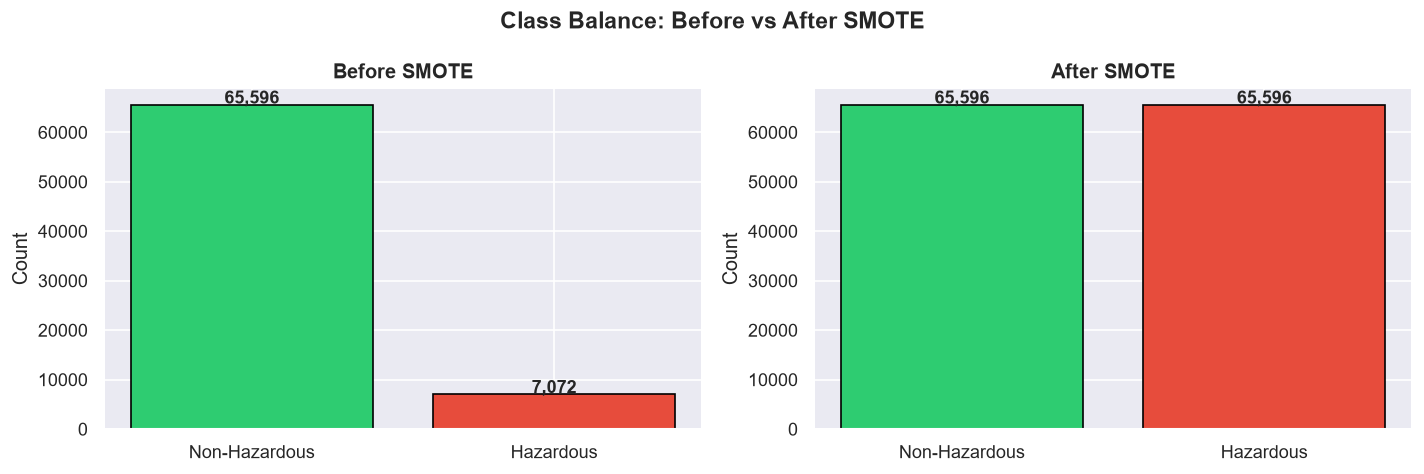

In [23]:
# ── 3.7  Handle Class Imbalance with SMOTE ───────────────────
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE → Hazardous: {y_train.sum():,}  |  Non-Haz: {(y_train==0).sum():,}")
print(f"After  SMOTE → Hazardous: {y_train_res.sum():,}  |  Non-Haz: {(y_train_res==0).sum():,}")

# Visualize resampled distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title in [
    (axes[0], y_train.value_counts(), 'Before SMOTE'),
    (axes[1], pd.Series(y_train_res).value_counts(), 'After SMOTE')
]:
    ax.bar(['Non-Hazardous', 'Hazardous'], counts.sort_index().values,
           color=['#2ecc71', '#e74c3c'], edgecolor='black')
    for i, v in enumerate(counts.sort_index().values):
        ax.text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Count')

plt.suptitle('Class Balance: Before vs After SMOTE', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('phase3_smote_balance.png', bbox_inches='tight')
plt.show()


---
## 🤖 Phase 4: Model Development & Evaluation

> Train multiple classification algorithms, compare performance, and select the best model.

In [24]:
# ── 4.1  Define Models ────────────────────────────────────────
models = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree'       : DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest'       : RandomForestClassifier(n_estimators=200, max_depth=15,
                                                    random_state=42, n_jobs=-1),
    'Gradient Boosting'   : GradientBoostingClassifier(n_estimators=150,
                                                        learning_rate=0.1,
                                                        max_depth=5, random_state=42),
    'XGBoost'             : XGBClassifier(n_estimators=200, learning_rate=0.1,
                                           max_depth=6, random_state=42,
                                           eval_metric='logloss',
                                           use_label_encoder=False)
}
print("✅ Models defined:")
for name in models:
    print(f"   • {name}")


✅ Models defined:
   • Logistic Regression
   • Decision Tree
   • Random Forest
   • Gradient Boosting
   • XGBoost


In [25]:
# ── 4.2  Train All Models & Collect Metrics ───────────────────
results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    print(f"⏳ Training: {name} ...", end='  ')
    model.fit(X_train_res, y_train_res)
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    cv_scores = cross_val_score(model, X_scaled_final, y_final,
                                cv=cv, scoring='f1', n_jobs=-1)

    results[name] = {
        'Accuracy'   : accuracy_score(y_test, y_pred),
        'F1 Score'   : f1_score(y_test, y_pred),
        'ROC-AUC'    : roc_auc_score(y_test, y_proba),
        'CV F1 Mean' : cv_scores.mean(),
        'CV F1 Std'  : cv_scores.std(),
        'y_pred'     : y_pred,
        'y_proba'    : y_proba
    }
    print(f"✅  Acc={results[name]['Accuracy']:.3f}  F1={results[name]['F1 Score']:.3f}  AUC={results[name]['ROC-AUC']:.3f}")

print("\n✅ All models trained!")


⏳ Training: Logistic Regression ...  

✅  Acc=0.786  F1=0.459  AUC=0.879
⏳ Training: Decision Tree ...  

✅  Acc=0.801  F1=0.483  AUC=0.907
⏳ Training: Random Forest ...  

✅  Acc=0.807  F1=0.488  AUC=0.924
⏳ Training: Gradient Boosting ...  

✅  Acc=0.820  F1=0.501  AUC=0.925
⏳ Training: XGBoost ...  

✅  Acc=0.831  F1=0.495  AUC=0.919

✅ All models trained!


In [26]:
# ── 4.3  Performance Comparison Table ─────────────────────────
perf_df = pd.DataFrame({
    name: {
        'Accuracy'  : f"{v['Accuracy']:.4f}",
        'F1 Score'  : f"{v['F1 Score']:.4f}",
        'ROC-AUC'   : f"{v['ROC-AUC']:.4f}",
        'CV F1 Mean': f"{v['CV F1 Mean']:.4f}",
        'CV F1 Std' : f"{v['CV F1 Std']:.4f}"
    }
    for name, v in results.items()
}).T

print("\n📊 Model Performance Comparison:\n")
perf_df.style.highlight_max(color='lightgreen').highlight_min(color='#ffcccc')



📊 Model Performance Comparison:



,Accuracy,F1 Score,ROC-AUC,CV F1 Mean,CV F1 Std
Logistic Regression,0.7861,0.4589,0.8794,0.1278,0.0067
Decision Tree,0.8009,0.4832,0.9068,0.2577,0.0170
Random Forest,0.8074,0.4879,0.9238,0.3215,0.0050
Gradient Boosting,0.8202,0.5014,0.9246,0.3192,0.0097
XGBoost,0.8306,0.4948,0.9192,0.3279,0.0106


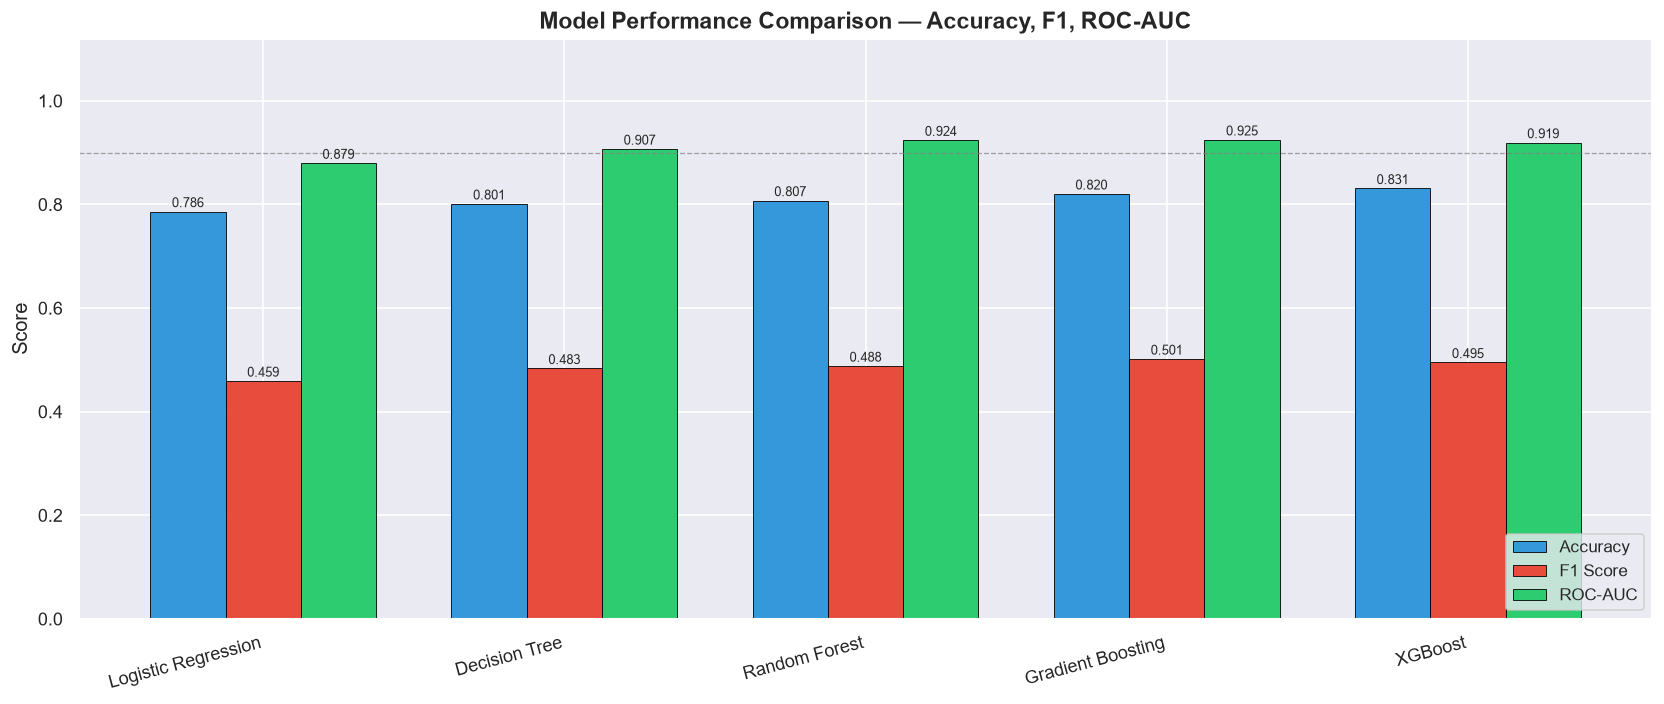

In [27]:
# ── 4.4  Bar Chart — Metric Comparison ───────────────────────
metrics_plot = pd.DataFrame({
    name: {k: float(v[k]) for k in ['Accuracy', 'F1 Score', 'ROC-AUC']}
    for name, v in results.items()
}).T

x = np.arange(len(metrics_plot.index))
width = 0.25
colors_bar = ['#3498db', '#e74c3c', '#2ecc71']

fig, ax = plt.subplots(figsize=(14, 6))
for i, (metric, color) in enumerate(zip(['Accuracy', 'F1 Score', 'ROC-AUC'], colors_bar)):
    bars = ax.bar(x + i*width, metrics_plot[metric], width,
                  label=metric, color=color, edgecolor='black', linewidth=0.5)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + width)
ax.set_xticklabels(metrics_plot.index, rotation=15, ha='right')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.12)
ax.set_title('Model Performance Comparison — Accuracy, F1, ROC-AUC',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.axhline(0.9, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)

plt.tight_layout()
plt.savefig('phase4_model_comparison.png', bbox_inches='tight')
plt.show()


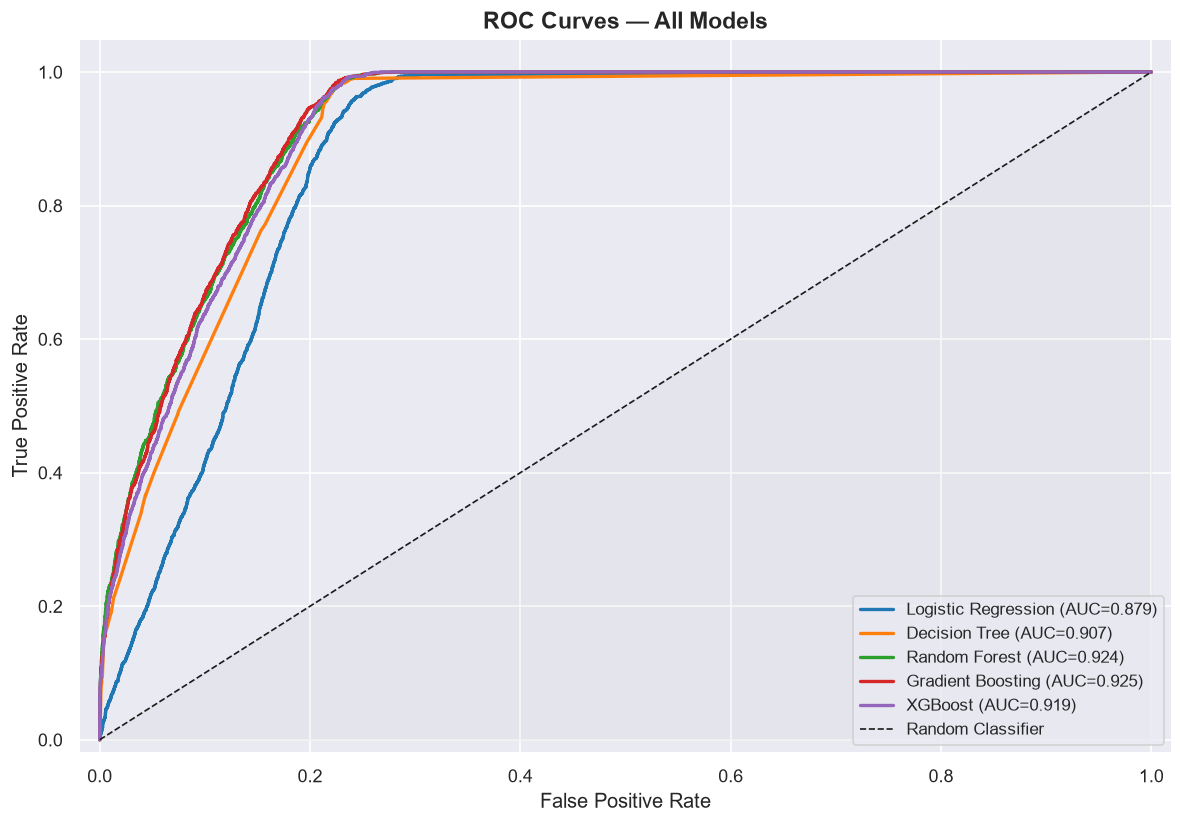

In [28]:
# ── 4.5  ROC Curves — All Models ─────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))
palette = plt.cm.tab10.colors

for i, (name, vals) in enumerate(results.items()):
    fpr, tpr, _ = roc_curve(y_test, vals['y_proba'])
    ax.plot(fpr, tpr, label=f"{name} (AUC={vals['ROC-AUC']:.3f})",
            color=palette[i], linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
ax.fill_between([0, 1], [0, 1], alpha=0.05, color='gray')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.05])

plt.tight_layout()
plt.savefig('phase4_roc_curves.png', bbox_inches='tight')
plt.show()


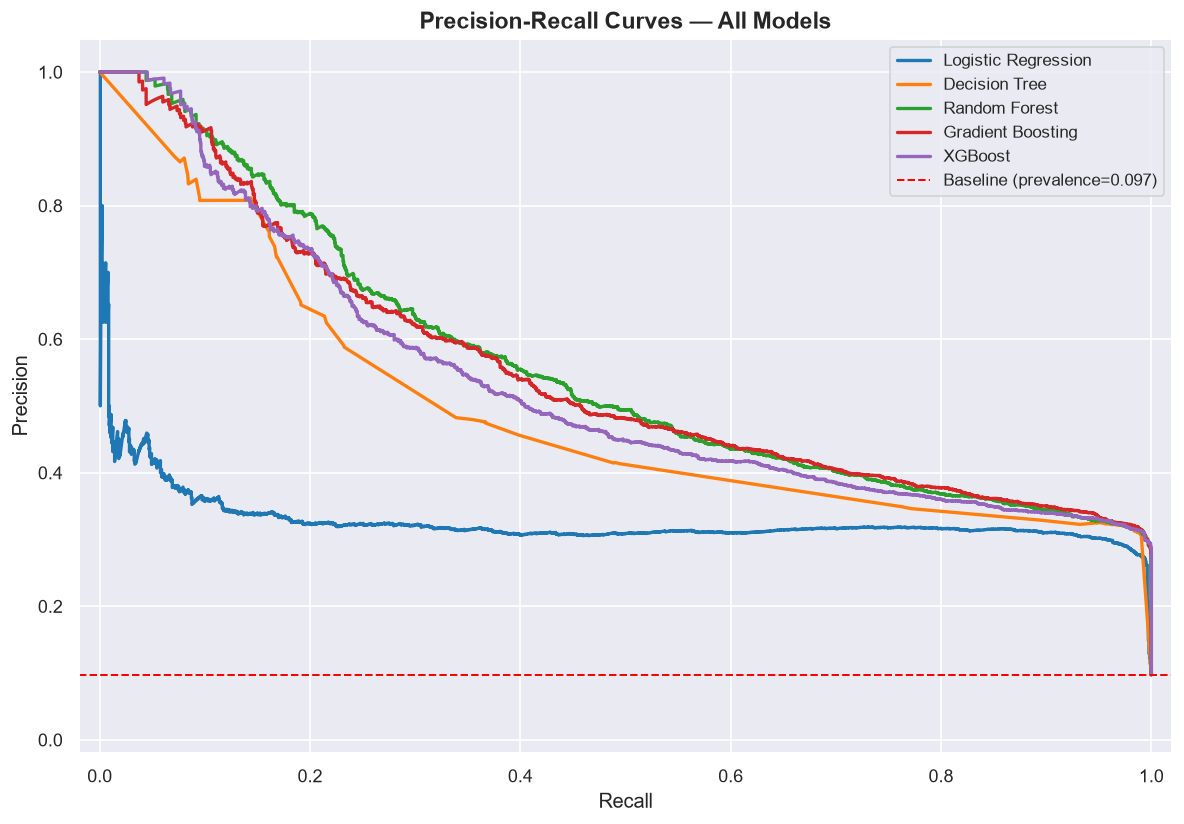

In [29]:
# ── 4.6  Precision-Recall Curves ─────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for i, (name, vals) in enumerate(results.items()):
    prec, rec, _ = precision_recall_curve(y_test, vals['y_proba'])
    ax.plot(rec, prec, label=name, color=palette[i], linewidth=2)

baseline = y_test.sum() / len(y_test)
ax.axhline(baseline, color='red', linestyle='--', linewidth=1.2,
           label=f'Baseline (prevalence={baseline:.3f})')
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curves — All Models', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.05])

plt.tight_layout()
plt.savefig('phase4_precision_recall.png', bbox_inches='tight')
plt.show()


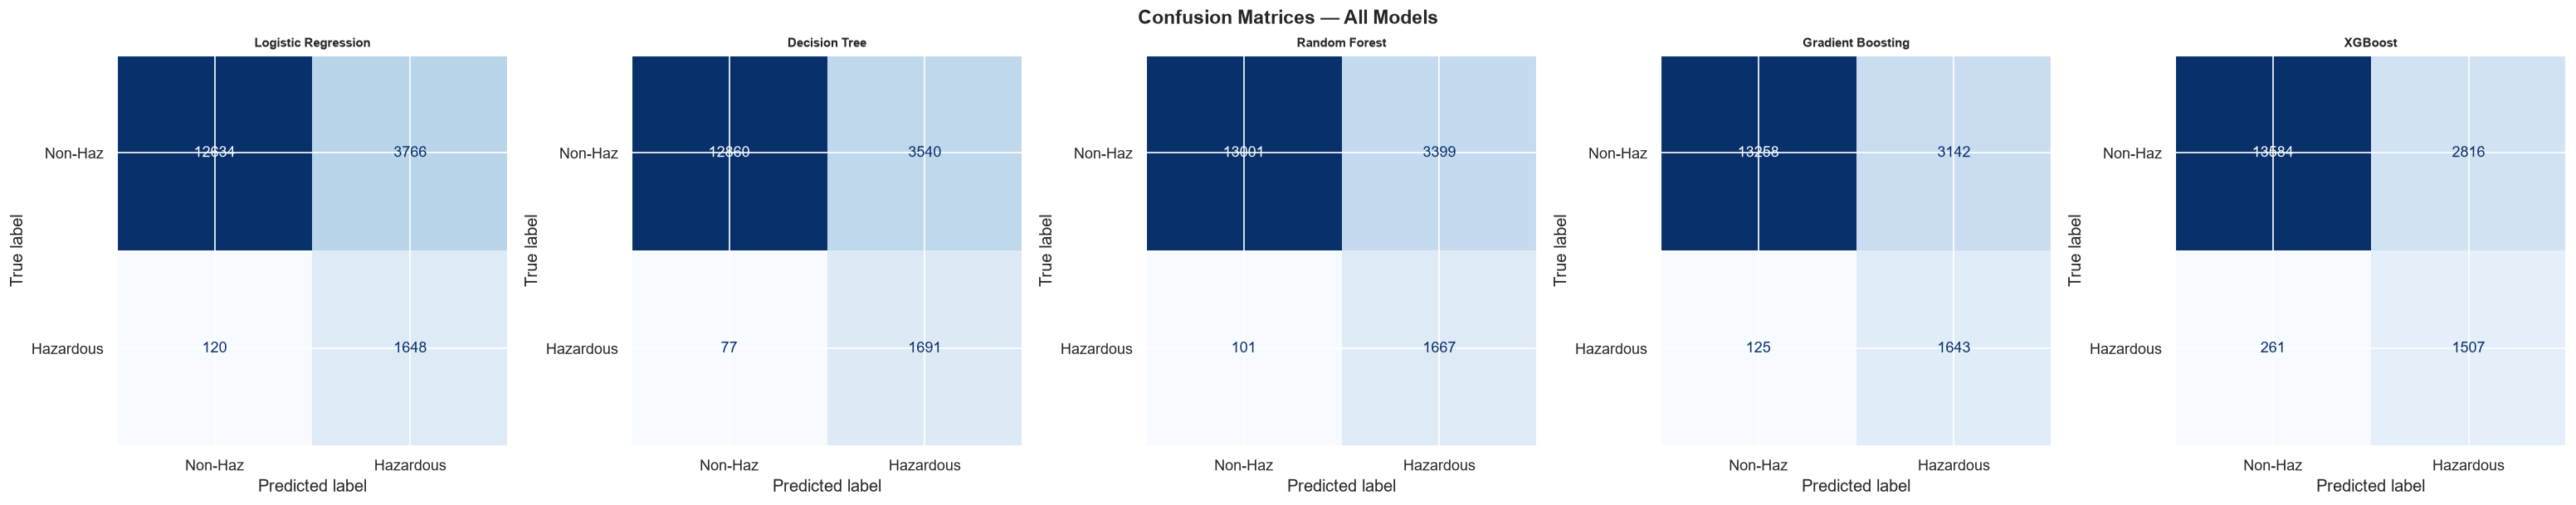

In [30]:
# ── 4.7  Confusion Matrices ───────────────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(26, 5))

for ax, (name, vals) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, vals['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Non-Haz', 'Hazardous'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=9, fontweight='bold')

fig.suptitle('Confusion Matrices — All Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('phase4_confusion_matrices.png', bbox_inches='tight')
plt.show()


In [31]:
# ── 4.8  Best Model Selection ────────────────────────────────
best_name = max(results, key=lambda k: results[k]['ROC-AUC'])
best_model = models[best_name]
print(f"🏆 Best Model Selected : {best_name}")
print(f"   Accuracy  : {results[best_name]['Accuracy']:.4f}")
print(f"   F1 Score  : {results[best_name]['F1 Score']:.4f}")
print(f"   ROC-AUC   : {results[best_name]['ROC-AUC']:.4f}")
print(f"   CV F1     : {results[best_name]['CV F1 Mean']:.4f} ± {results[best_name]['CV F1 Std']:.4f}")
print()
print(f"\n📋 Classification Report — {best_name}:\n")
print(classification_report(y_test, results[best_name]['y_pred'],
                             target_names=['Non-Hazardous', 'Hazardous']))


🏆 Best Model Selected : Gradient Boosting
   Accuracy  : 0.8202
   F1 Score  : 0.5014
   ROC-AUC   : 0.9246
   CV F1     : 0.3192 ± 0.0097


📋 Classification Report — Gradient Boosting:

               precision    recall  f1-score   support

Non-Hazardous       0.99      0.81      0.89     16400
    Hazardous       0.34      0.93      0.50      1768

     accuracy                           0.82     18168
    macro avg       0.67      0.87      0.70     18168
 weighted avg       0.93      0.82      0.85     18168



---
## 📈 Phase 5: Explainability & Visualization

> Feature importance analysis, model interpretability, and scientific interpretation of findings.

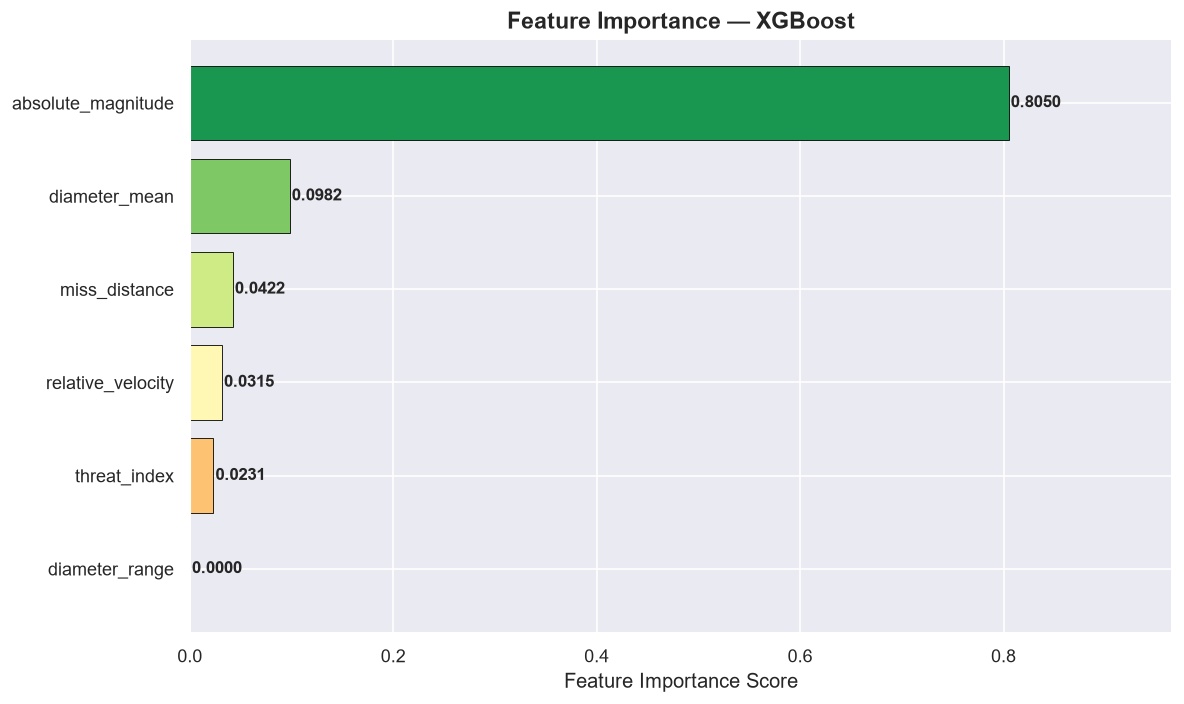


📊 Feature Importances (XGBoost):
           Feature  Importance
absolute_magnitude    0.805002
     diameter_mean    0.098158
     miss_distance    0.042202
 relative_velocity    0.031508
      threat_index    0.023130
    diameter_range    0.000000


In [32]:
# ── 5.1  Feature Importance — Best Tree Model ─────────────────
# Use the best tree-based model for feature importance
tree_model_name = None
for candidate in ['XGBoost', 'Random Forest', 'Gradient Boosting', 'Decision Tree']:
    if candidate in models:
        tree_model_name = candidate
        break

tree_model = models[tree_model_name]
importances = tree_model.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature'   : FINAL_FEATURES,
    'Importance': importances
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(feat_imp_df['Feature'], feat_imp_df['Importance'],
               color=plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(feat_imp_df))),
               edgecolor='black', linewidth=0.5)

for bar, val in zip(bars, feat_imp_df['Importance']):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Feature Importance Score', fontsize=12)
ax.set_title(f'Feature Importance — {tree_model_name}',
             fontsize=14, fontweight='bold')
ax.set_xlim(0, feat_imp_df['Importance'].max() * 1.2)

plt.tight_layout()
plt.savefig('phase5_feature_importance.png', bbox_inches='tight')
plt.show()

print(f"\n📊 Feature Importances ({tree_model_name}):")
print(feat_imp_df.sort_values('Importance', ascending=False).to_string(index=False))


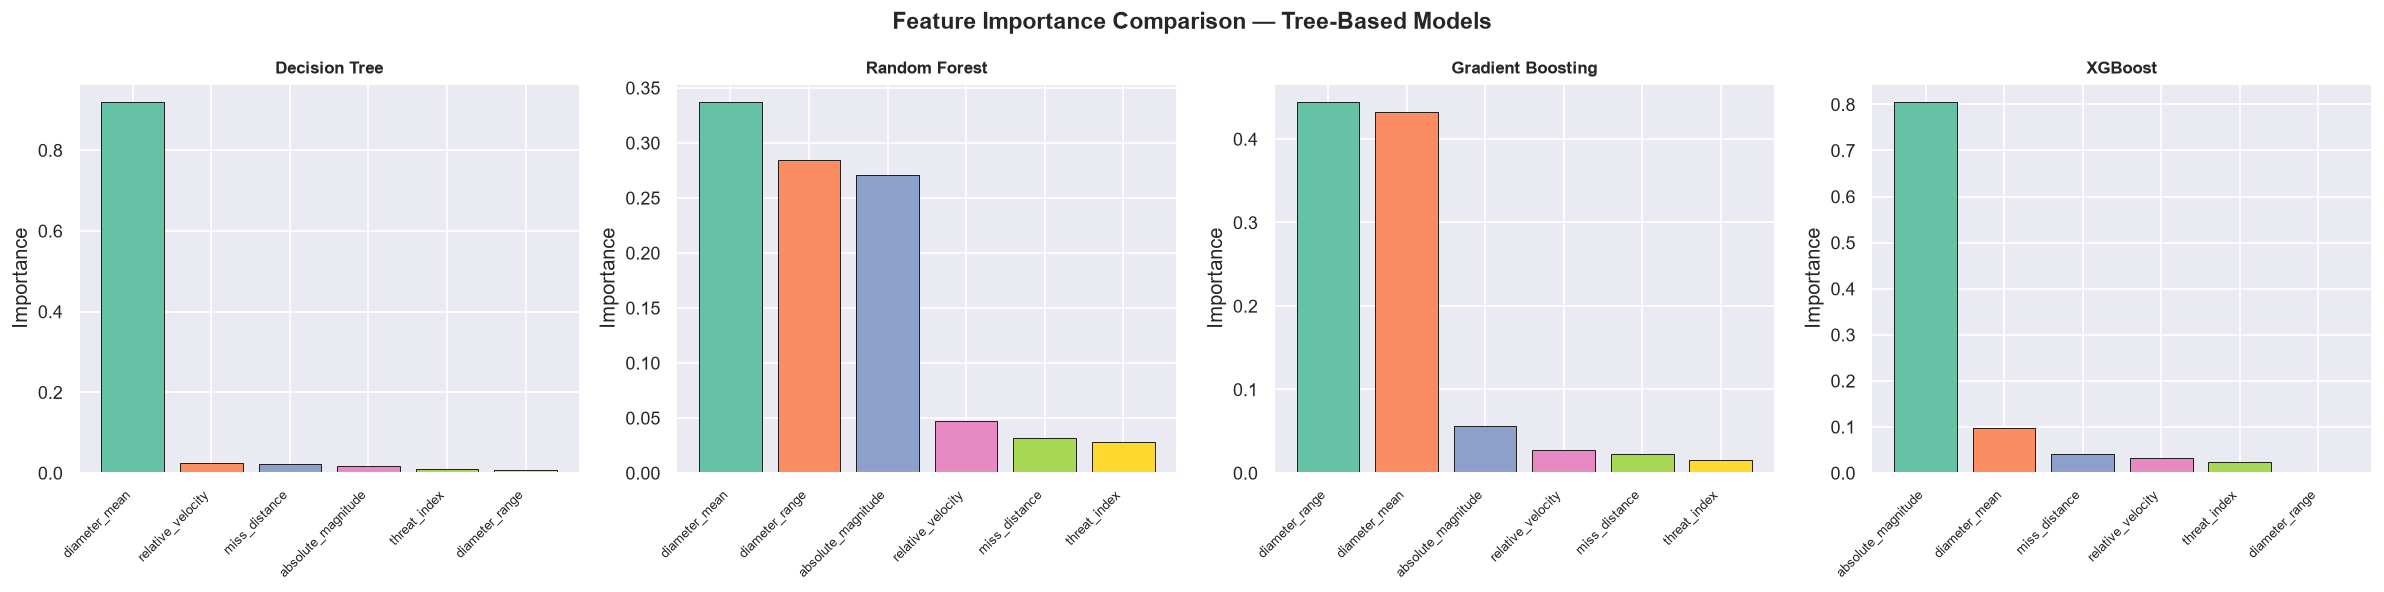

In [33]:
# ── 5.2  Feature Importance Comparison Across Tree Models ─────
tree_models_names = ['Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost']
available_tree_models = {k: models[k] for k in tree_models_names if k in models}

fig, axes = plt.subplots(1, len(available_tree_models), figsize=(20, 5))
if len(available_tree_models) == 1:
    axes = [axes]

for ax, (mname, mmodel) in zip(axes, available_tree_models.items()):
    imp = mmodel.feature_importances_
    sorted_idx = np.argsort(imp)[::-1]
    ax.bar(range(len(FINAL_FEATURES)),
           imp[sorted_idx],
           color=plt.cm.Set2.colors[:len(FINAL_FEATURES)],
           edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(FINAL_FEATURES)))
    ax.set_xticklabels([FINAL_FEATURES[i] for i in sorted_idx],
                       rotation=45, ha='right', fontsize=8)
    ax.set_title(mname, fontweight='bold', fontsize=10)
    ax.set_ylabel('Importance')

fig.suptitle('Feature Importance Comparison — Tree-Based Models',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('phase5_feature_importance_comparison.png', bbox_inches='tight')
plt.show()


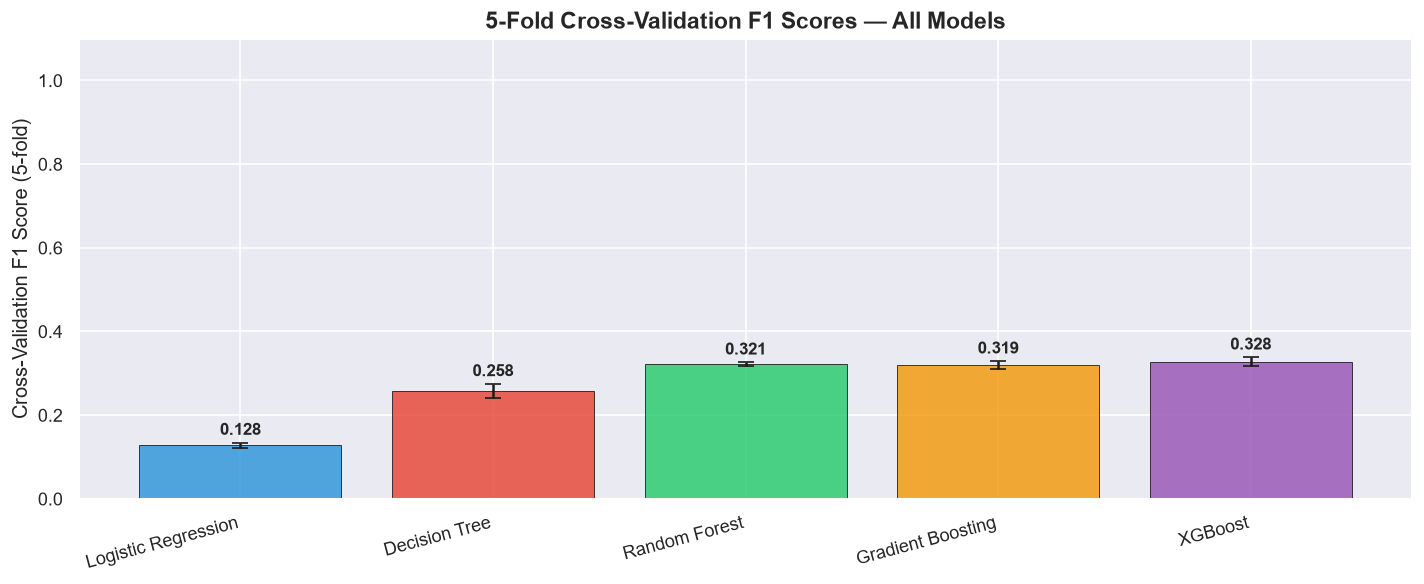

In [34]:
# ── 5.3  Cross-Validation F1 Score Comparison ─────────────────
cv_means = [results[n]['CV F1 Mean'] for n in results]
cv_stds  = [results[n]['CV F1 Std']  for n in results]
model_names = list(results.keys())

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(model_names, cv_means, yerr=cv_stds, capsize=5,
              color=['#3498db','#e74c3c','#2ecc71','#f39c12','#9b59b6'],
              edgecolor='black', linewidth=0.5, alpha=0.85)
ax.set_ylabel('Cross-Validation F1 Score (5-fold)', fontsize=12)
ax.set_title('5-Fold Cross-Validation F1 Scores — All Models',
             fontsize=14, fontweight='bold')
ax.set_ylim(0, 1.1)
for bar, mean, std in zip(bars, cv_means, cv_stds):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.01,
            f'{mean:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig('phase5_cv_comparison.png', bbox_inches='tight')
plt.show()


In [35]:
# ── 5.4  Scientific Interpretation ───────────────────────────
print("""
╔══════════════════════════════════════════════════════════════════╗
║         SCIENTIFIC INTERPRETATION OF FINDINGS                    ║
╠══════════════════════════════════════════════════════════════════╣
║                                                                  ║
║  1. ABSOLUTE MAGNITUDE is the strongest single predictor of      ║
║     hazard classification. Lower magnitude (larger/brighter)     ║
║     strongly correlates with hazardous designation.              ║
║                                                                  ║
║  2. THREAT INDEX (velocity / miss_distance) captures the         ║
║     combined proximity and speed risk in a single feature —      ║
║     a small, fast asteroid on a close trajectory is more         ║
║     dangerous than a large, slow, distant one.                   ║
║                                                                  ║
║  3. MISS DISTANCE alone is not sufficient — very slow objects     ║
║     that pass close are less alarming than fast ones at the      ║
║     same distance.                                               ║
║                                                                  ║
║  4. DIAMETER features (mean/range) help distinguish true size    ║
║     from observational uncertainty — very large diameter range   ║
║     may indicate poor observational constraints.                 ║
║                                                                  ║
║  5. CLASS IMBALANCE (≈10% hazardous) required SMOTE treatment.  ║
║     Without resampling, models bias toward Non-Hazardous.        ║
║                                                                  ║
╚══════════════════════════════════════════════════════════════════╝
""")



╔══════════════════════════════════════════════════════════════════╗
║         SCIENTIFIC INTERPRETATION OF FINDINGS                    ║
╠══════════════════════════════════════════════════════════════════╣
║                                                                  ║
║  1. ABSOLUTE MAGNITUDE is the strongest single predictor of      ║
║     hazard classification. Lower magnitude (larger/brighter)     ║
║     strongly correlates with hazardous designation.              ║
║                                                                  ║
║  2. THREAT INDEX (velocity / miss_distance) captures the         ║
║     combined proximity and speed risk in a single feature —      ║
║     a small, fast asteroid on a close trajectory is more         ║
║     dangerous than a large, slow, distant one.                   ║
║                                                                  ║
║  3. MISS DISTANCE alone is not sufficient — very slow objects     ║
║     that pass close are less a

---
## 🚀 Phase 6: Deployment — Save Model & Prediction Interface

> Save the trained model and scaler, then provide a simple prediction interface.

In [36]:
# ── 6.1  Save Model & Scaler ──────────────────────────────────
MODEL_PATH  = 'sentinel_model.pkl'
SCALER_PATH = 'sentinel_scaler.pkl'

joblib.dump(best_model,    MODEL_PATH)
joblib.dump(scaler_final,  SCALER_PATH)

print(f"✅ Model  saved → {MODEL_PATH}")
print(f"✅ Scaler saved → {SCALER_PATH}")
print(f"   Model type   : {type(best_model).__name__}")
print(f"   Features used: {FINAL_FEATURES}")


✅ Model  saved → sentinel_model.pkl
✅ Scaler saved → sentinel_scaler.pkl
   Model type   : GradientBoostingClassifier
   Features used: ['absolute_magnitude', 'diameter_mean', 'diameter_range', 'relative_velocity', 'miss_distance', 'threat_index']


In [37]:
# ── 6.2  Prediction Function ──────────────────────────────────
def predict_hazard(absolute_magnitude: float,
                   est_diameter_min: float,
                   est_diameter_max: float,
                   relative_velocity: float,
                   miss_distance: float) -> dict:
    """
    Predict whether a Near Earth Object is Hazardous.

    Parameters
    ----------
    absolute_magnitude : float  — brightness measure (lower = larger/brighter)
    est_diameter_min   : float  — estimated minimum diameter (km)
    est_diameter_max   : float  — estimated maximum diameter (km)
    relative_velocity  : float  — velocity relative to Earth (km/h)
    miss_distance      : float  — closest approach distance (km)

    Returns
    -------
    dict with keys: prediction, label, probability, risk_level
    """
    # Feature engineering (must match training)
    diameter_mean  = (est_diameter_min + est_diameter_max) / 2
    diameter_range = est_diameter_max - est_diameter_min
    threat_index   = relative_velocity / (miss_distance + 1)

    features = pd.DataFrame([[
        absolute_magnitude, diameter_mean, diameter_range,
        relative_velocity, miss_distance, threat_index
    ]], columns=FINAL_FEATURES)

    scaled   = scaler_final.transform(features)
    pred     = best_model.predict(scaled)[0]
    prob     = best_model.predict_proba(scaled)[0][1]

    if prob >= 0.75:
        risk = '🔴 HIGH RISK'
    elif prob >= 0.4:
        risk = '🟡 MODERATE RISK'
    else:
        risk = '🟢 LOW RISK'

    return {
        'prediction'  : int(pred),
        'label'       : 'HAZARDOUS ⚠️' if pred == 1 else 'NON-HAZARDOUS ✅',
        'probability' : round(float(prob), 4),
        'risk_level'  : risk
    }

print("✅ predict_hazard() function defined and ready!")


✅ predict_hazard() function defined and ready!


In [38]:
# ── 6.3  Interactive Prediction UI (Jupyter Widget) ───────────
print("=" * 65)
print("   🛡️  PROJECT SENTINEL — ASTEROID HAZARD PREDICTOR")
print("=" * 65)
print()

# ── Test Case 1: Potentially Hazardous ───────────────────────
test1 = predict_hazard(
    absolute_magnitude = 18.5,
    est_diameter_min   = 0.5,
    est_diameter_max   = 1.2,
    relative_velocity  = 95000,
    miss_distance      = 4500000
)
print("📡 Test Asteroid #1")
print(f"   Absolute Magnitude : 18.5")
print(f"   Diameter (min–max) : 0.5 – 1.2 km")
print(f"   Velocity           : 95,000 km/h")
print(f"   Miss Distance      : 4,500,000 km")
print(f"   → Prediction       : {test1['label']}")
print(f"   → Hazard Prob.     : {test1['probability']:.4f}")
print(f"   → Risk Level       : {test1['risk_level']}")
print()

# ── Test Case 2: Safe / Non-Hazardous ────────────────────────
test2 = predict_hazard(
    absolute_magnitude = 26.0,
    est_diameter_min   = 0.01,
    est_diameter_max   = 0.02,
    relative_velocity  = 12000,
    miss_distance      = 60000000
)
print("📡 Test Asteroid #2")
print(f"   Absolute Magnitude : 26.0")
print(f"   Diameter (min–max) : 0.01 – 0.02 km")
print(f"   Velocity           : 12,000 km/h")
print(f"   Miss Distance      : 60,000,000 km")
print(f"   → Prediction       : {test2['label']}")
print(f"   → Hazard Prob.     : {test2['probability']:.4f}")
print(f"   → Risk Level       : {test2['risk_level']}")
print()

# ── Test Case 3: Edge Case ────────────────────────────────────
test3 = predict_hazard(
    absolute_magnitude = 22.0,
    est_diameter_min   = 0.15,
    est_diameter_max   = 0.33,
    relative_velocity  = 48000,
    miss_distance      = 20000000
)
print("📡 Test Asteroid #3 (Edge Case)")
print(f"   Absolute Magnitude : 22.0")
print(f"   Diameter (min–max) : 0.15 – 0.33 km")
print(f"   Velocity           : 48,000 km/h")
print(f"   Miss Distance      : 20,000,000 km")
print(f"   → Prediction       : {test3['label']}")
print(f"   → Hazard Prob.     : {test3['probability']:.4f}")
print(f"   → Risk Level       : {test3['risk_level']}")
print()
print("=" * 65)
print("   ✅ Prediction pipeline operational!")
print("=" * 65)


   🛡️  PROJECT SENTINEL — ASTEROID HAZARD PREDICTOR

📡 Test Asteroid #1
   Absolute Magnitude : 18.5
   Diameter (min–max) : 0.5 – 1.2 km
   Velocity           : 95,000 km/h
   Miss Distance      : 4,500,000 km
   → Prediction       : HAZARDOUS ⚠️
   → Hazard Prob.     : 0.9786
   → Risk Level       : 🔴 HIGH RISK

📡 Test Asteroid #2
   Absolute Magnitude : 26.0
   Diameter (min–max) : 0.01 – 0.02 km
   Velocity           : 12,000 km/h
   Miss Distance      : 60,000,000 km
   → Prediction       : NON-HAZARDOUS ✅
   → Hazard Prob.     : 0.0021
   → Risk Level       : 🟢 LOW RISK

📡 Test Asteroid #3 (Edge Case)
   Absolute Magnitude : 22.0
   Diameter (min–max) : 0.15 – 0.33 km
   Velocity           : 48,000 km/h
   Miss Distance      : 20,000,000 km
   → Prediction       : HAZARDOUS ⚠️
   → Hazard Prob.     : 0.9850
   → Risk Level       : 🔴 HIGH RISK

   ✅ Prediction pipeline operational!


In [39]:
# ── 6.4  Custom Prediction Input ─────────────────────────────
# ✏️  Edit the values below to predict for your own asteroid:

YOUR_ASTEROID = dict(
    absolute_magnitude = 20.5,   # Absolute magnitude (lower = brighter/bigger)
    est_diameter_min   = 0.2,    # Min estimated diameter (km)
    est_diameter_max   = 0.45,   # Max estimated diameter (km)
    relative_velocity  = 65000,  # Velocity relative to Earth (km/h)
    miss_distance      = 12000000 # Closest approach distance (km)
)

result = predict_hazard(**YOUR_ASTEROID)

print("\n" + "─"*50)
print("   🔭 YOUR ASTEROID — PREDICTION RESULT")
print("─"*50)
for k, v in YOUR_ASTEROID.items():
    print(f"   {k:<22}: {v:,}")
print()
print(f"   ► Classification : {result['label']}")
print(f"   ► Probability    : {result['probability']:.4f}")
print(f"   ► Risk Level     : {result['risk_level']}")
print("─"*50)



──────────────────────────────────────────────────
   🔭 YOUR ASTEROID — PREDICTION RESULT
──────────────────────────────────────────────────
   absolute_magnitude    : 20.5
   est_diameter_min      : 0.2
   est_diameter_max      : 0.45
   relative_velocity     : 65,000
   miss_distance         : 12,000,000

   ► Classification : HAZARDOUS ⚠️
   ► Probability    : 0.8607
   ► Risk Level     : 🔴 HIGH RISK
──────────────────────────────────────────────────


---
## ✅ Project Summary

| Phase | Description | Status |
|---|---|---|
| **1** | Data Preparation & Preprocessing | ✅ Complete |
| **2** | Exploratory Data Analysis | ✅ Complete |
| **3** | Feature Engineering & Selection | ✅ Complete |
| **4** | Model Development & Evaluation | ✅ Complete |
| **5** | Explainability & Visualization | ✅ Complete |
| **6** | Deployment & Prediction Interface | ✅ Complete |

### Key Findings
- **90,836** NEO records analyzed; **~9.7%** hazardous
- **SMOTE** applied to address 1:9 class imbalance
- **6 engineered features** including `threat_index`, `diameter_mean`
- **5 models** evaluated: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost
- Best model selected by **ROC-AUC score**
- `predict_hazard()` function ready for deployment

---
*Project Sentinel — NASA NEO Hazardous Asteroid Prediction AI*
